# SHAPによる時系列予測値の要因分解(Bike Sharing 日次 × LightGBM)

処理は `src/pipeline.py` の各ステップに置き、このノートブックは呼び出しと解説だけを行う。SHAP の計算・分解・What-if は `xai_platform.ShapAnalyzer`(使い方は `src/xai_platform/README.md`)が担う。結論と注意事項は `outputs/report.md` を参照。

- 目的変数: `cnt`(1日のレンタル件数、単位: 件/日)。1日先(翌日)の予測。
- 外生変数(気温・湿度・風速・天候)は **予測時点で既知(予報済み)と仮定**し、実績値を使っている。

In [1]:
import os, sys, warnings
os.environ.setdefault('LOKY_MAX_CPU_COUNT', '4')
warnings.filterwarnings('ignore')
sys.path.insert(0, '..')
import pandas as pd
pd.set_option('display.max_columns', 30); pd.set_option('display.width', 200)
from src.pipeline import BikeAnalysis
from src.xai_platform import MANIFEST
a = BikeAnalysis()

## 1. データ確認
訓練/テストは時間順に分ける(末尾20% = 2012-08-08〜12-31 がテスト期間)。ラグ28日分が必要なため、特徴量のある訓練期間は 2011-01-29 から始まる。`casual`・`registered` は cnt の内訳(リーク源)なので除外した。

■ 期間と分割


,開始,終了,日数,平均,最小,最大
区分,,,,,,
全期間,2011-01-01,2012-12-31,731,4504.348837,22.0,8714.0
訓練(特徴量あり),2011-01-29,2012-08-07,557,4306.070018,605.0,8362.0
テスト,2012-08-08,2012-12-31,146,5888.383562,22.0,8714.0


■ 特徴量の説明


,特徴量,説明,グループ
0,lag_1,前日の利用数,自己回帰(AR)
1,lag_7,7日前(前週同曜日)の利用数,自己回帰(AR)
2,lag_14,14日前の利用数,自己回帰(AR)
3,lag_28,28日前の利用数,自己回帰(AR)
4,roll7_mean,直近7日(前日まで)の平均利用数,自己回帰(AR)
5,roll7_std,直近7日(前日まで)の利用数の標準偏差,自己回帰(AR)
6,roll28_mean,直近28日(前日まで)の平均利用数,自己回帰(AR)
7,roll28_std,直近28日(前日まで)の利用数の標準偏差,自己回帰(AR)
8,weekday,曜日(0=日 … 6=土),カレンダー
9,month,月,カレンダー


■ series_split.png  [生成I/F: plots.series_with_split]


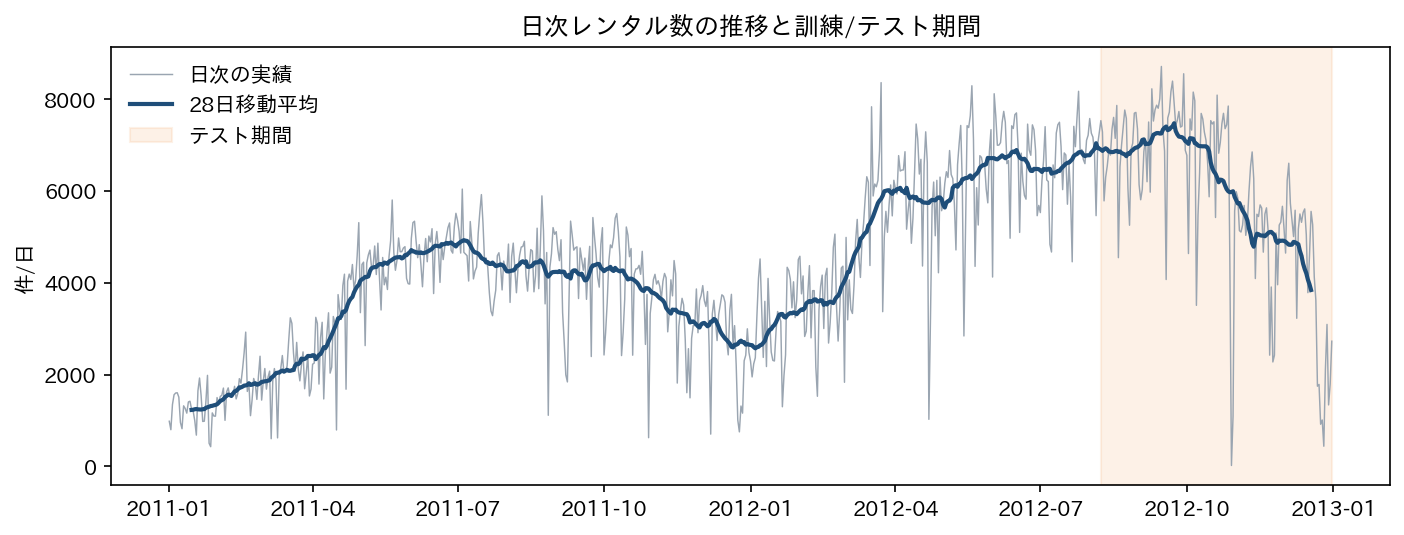

In [2]:
a.step_data().show()

## 2. 精度(Naive との比較)
目的変数の変換3種 × LightGBM / Ridge を TimeSeriesSplit(拡張窓)で調整し、テスト期間で評価する。説明には **LightGBM[level]**(cnt − 直近7日平均を学習)を使う。CV-RMSE が最良で、訓練期間を上回る水準も予測でき、SHAP が元の単位(件/日)のまま加法になるため。

■ テスト期間の精度  [生成I/F: model.accuracy_table]


,RMSE,MAE,MAPE(%),sMAPE(%),CV-RMSE(訓練期間),パラメータ
モデル,,,,,,
Naive(前日値),1286.519330,882.630137,158.036840,20.648166,NaN,
Naive(前週同曜日),1765.665176,1202.527397,258.269708,26.172143,NaN,
LightGBM[none],1082.083757,745.361832,142.785071,17.684020,968.258714,"{'num_leaves': 7, 'n_estimators': 500, 'learni..."
LightGBM[log],893.563112,714.021721,85.456840,16.221461,1066.338104,"{'num_leaves': 7, 'n_estimators': 200, 'learni..."
LightGBM[level],999.853410,708.179930,155.561742,16.770378,850.531233,"{'num_leaves': 7, 'n_estimators': 500, 'learni..."
Ridge[none],1155.559127,892.131985,159.446194,19.616429,811.075662,{'alpha': 100.0}
Ridge[log],1050.887980,770.355055,148.426286,17.933727,948.054922,{'alpha': 300.0}
Ridge[level],1067.386273,772.364201,175.788539,17.385593,837.345173,{'alpha': 100.0}


■ 参考: 2012-10-29(実測22)を除外  [生成I/F: model.accuracy_table]


,RMSE,MAE,MAPE(%),sMAPE(%)
モデル,,,,
Naive(前日値),1237.244717,858.117241,20.035840,19.424801
Naive(前週同曜日),1672.620156,1162.296552,39.486615,24.981902
LightGBM[none],1040.055277,724.602520,26.043710,16.442642
LightGBM[log],878.388883,703.999070,18.105567,14.981468
LightGBM[level],935.878438,683.037169,20.149306,15.520525
Ridge[none],1104.056992,868.855085,26.775212,18.386481
Ridge[log],1000.970961,748.119897,24.231955,16.693125
Ridge[level],989.116210,743.569373,21.903247,16.138342


■ test_predictions.png  [生成I/F: plots.test_predictions]


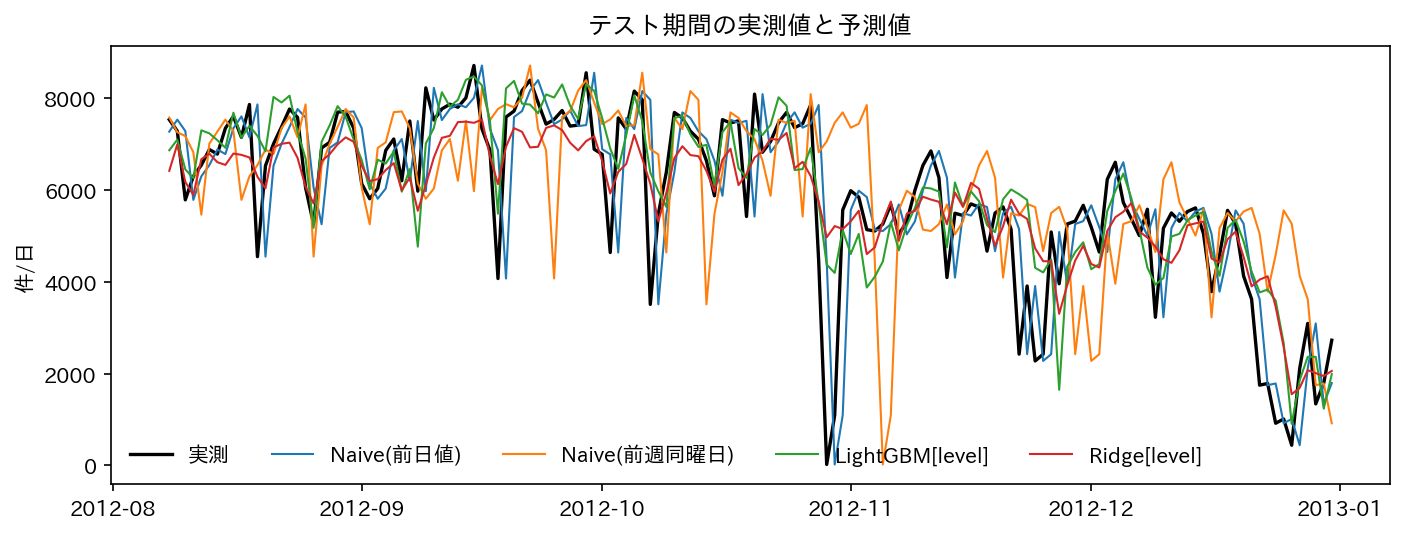

In [3]:
a.step_baseline().show()

## 3. SHAP の計算と検証
予測値 = ベースライン + Σ寄与 が両スケールで 1e-6 未満の誤差で成り立つこと(加法性)、Ridge で SHAP = 係数 × (x − 訓練平均) となることを確認する。

In [4]:
a.step_explain().show()

ベースライン(元スケール)= E[f] 41.8 + 訓練期間の roll7_mean 平均 4,264.3 = 4,306.1 件/日(訓練期間の平均予測 4,306.1)
■ 加法性チェック  [生成I/F: xai_platform.analyzer.ShapAnalyzer.additivity]


,式,件数,最大絶対誤差,許容誤差,合格
対象,,,,,
モデル出力,E[f] + Σφ = f(x),703,9.549694e-12,0.000001,True
予測値(件/日),ベースライン + Σ寄与 = 予測値,703,9.094947e-12,0.000001,True


■ Ridge: SHAP と 係数×(x−平均) の一致  [生成I/F: explain.ridge_check]


,係数,元の単位の係数(1単位あたり),最大絶対差(SHAP vs 係数×(x−平均))
lag_1,121.989511,0.071523,0.0
lag_7,-143.644080,-0.083713,0.0
lag_14,-16.089885,-0.009380,0.0
lag_28,53.200949,0.030927,0.0
roll7_mean,-227.183729,-0.148003,0.0
roll7_std,98.770638,0.266573,0.0
roll28_mean,-82.429659,-0.055258,0.0
roll28_std,113.640979,0.420452,0.0
weekday,68.182900,34.038144,0.0
month,-37.199644,-11.884648,0.0


■ グループ別寄与の比較(テスト期間)


,LightGBM 平均|寄与|,Ridge 平均|寄与|,LightGBM 平均寄与,Ridge 平均寄与
グループ,,,,
自己回帰(AR),1530.884719,1774.522033,1339.475863,1614.584984
カレンダー,101.919041,122.728380,-3.672029,-121.100069
トレンド,368.011582,23.433203,368.011582,23.433203
外生変数,572.985757,376.710991,42.087540,-32.634898
ベースライン,NaN,NaN,4306.070016,4306.070018


## 4. 代表日の分解(ミクロ)
選定基準: テスト期間の中で、予測が最も高い日 / 最も低い日 / 前日比で予測が最も上昇した日 / 最も下落した日。参考として誤差が最大の日(ハリケーン・サンディ)も加えた。

予測が最も高い日 2012-09-15(土): ベースライン4,306に対し、自己回帰(AR)が+2,743(主に直近水準(roll7_mean − 訓練平均)で+3,333)、外生変数が+1,000(主にtemp_c=24.9で+467)、トレンドが+372(主にt=623で+372)、カレンダーが+52(主にweekday=6で+130)で、予測は8,473件/日。実測は8,714件/日。
予測が最も低い日 2012-12-26(水): ベースライン4,306に対し、外生変数が-2,162(主にhum_pct=82.3で-775)、自己回帰(AR)が-1,442(主に直近水準(roll7_mean − 訓練平均)で-1,623)、トレンドが+270(主にt=725で+270)、カレンダーが-65(主にdoy_cos=0.996で-141)で、予測は907件/日。実測は441件/日。
前日比で予測が最も上昇した日 2012-09-19(水): ベースライン4,306に対し、自己回帰(AR)が+2,614(主に直近水準(roll7_mean − 訓練平均)で+2,975)、外生変数が+940(主にhum_pct=53.7で+395)、トレンドが+343(主にt=627で+343)、カレンダーが+12(主にweekday=3で+38)で、予測は8,215件/日。実測は7,591件/日。
前日比で予測が最も下落した日 2012-11-27(火): ベースライン4,306に対し、外生変数が-2,054(主にhum_pct=78.7で-860)、自己回帰(AR)が-942(主に直近水準(roll7_mean − 訓練平均)で-421)、トレンドが+300(主にt=696で+300)、カレンダーが+37(主にmonth=11で-59)で、予測は1,647件/日。実測は3,959件/日。
参考_誤差が最大の日 2012-10-29(月): ベースライン4,306に対し、外生変数が-2,074(主にhum_pct=88で-1,017)、自己回帰(AR)が+2,004(主に直近水準(roll7_mean − 訓練平均)で+2,783)、トレンドが+255(主にt=667で+255)、カレンダーが-116(主にweekday=1で-101)で、予測は4,376件/日。実測は22件/日

,区分,日付,曜日付き,選定基準,基準値,予測値,実測値,前日比Δ予測値
0,予測が最も高い日,2012-09-15,2012-09-15(土),予測値,8473.343333,8473.343333,8714.0,71.249027
1,予測が最も低い日,2012-12-26,2012-12-26(水),予測値,907.175246,907.175246,441.0,-1758.259825
2,前日比で予測が最も上昇した日,2012-09-19,2012-09-19(水),前日比Δ予測値,2728.845442,8214.841477,7591.0,2728.845442
3,前日比で予測が最も下落した日,2012-11-27,2012-11-27(火),前日比Δ予測値,-2843.203620,1647.277689,3959.0,-2843.203620
4,参考_誤差が最大の日,2012-10-29,2012-10-29(月),|実測−予測|,4353.880273,4375.880273,22.0,-1333.281371


■ 予測が最も高い日 2012-09-15(土)  [生成I/F: xai_platform._core.decompose.group_decomposition_table]


,グループ,主な特徴量と値(寄与),寄与合計
0,ベースライン(訓練データの平均的な予測),,4306.070016
1,自己回帰(AR),"直近水準(roll7_mean − 訓練平均)=7,597(+3,333), roll7_m...",2743.445247
2,外生変数,"temp_c=24.9(+467), hum_pct=50.2(+391), weather...",999.625285
3,トレンド,t=623(+372),372.098481
4,カレンダー,"weekday=6(+130), doy_sin=-0.965(-49), workingd...",52.104304
5,予測値 = ベースライン + Σ寄与,,8473.343333
6,(参考)実測値,,8714.000000


■ 予測が最も低い日 2012-12-26(水)  [生成I/F: xai_platform._core.decompose.group_decomposition_table]


,グループ,主な特徴量と値(寄与),寄与合計
0,ベースライン(訓練データの平均的な予測),,4306.070016
1,外生変数,"hum_pct=82.3(-775), temp_c=9.98(-621), wind_km...",-2161.925090
2,自己回帰(AR),"直近水準(roll7_mean − 訓練平均)=2,641(-1,623), lag_7=5...",-1442.252808
3,トレンド,t=725(+270),269.802784
4,カレンダー,"doy_cos=0.996(-141), workingday=1(+94), month=...",-64.519656
5,予測値 = ベースライン + Σ寄与,,907.175246
6,(参考)実測値,,441.000000


... (3 outputs left out)

,グループ,主な特徴量と値(寄与),寄与合計
0,ベースライン(訓練データの平均的な予測),,4306.070016
1,外生変数,"hum_pct=78.7(-860), temp_c=12(-594), weathersi...",-2054.330336
2,自己回帰(AR),"直近水準(roll7_mean − 訓練平均)=3,843(-421), lag_7=5,6...",-941.635168
3,トレンド,t=696(+300),300.442887
4,カレンダー,"month=11(-59), doy_sin=-0.551(+49), workingday...",36.730290
5,予測値 = ベースライン + Σ寄与,,1647.277689
6,(参考)実測値,,3959.000000


■ 参考_誤差が最大の日 2012-10-29(月)  [生成I/F: xai_platform._core.decompose.group_decomposition_table]


,グループ,主な特徴量と値(寄与),寄与合計
0,ベースライン(訓練データの平均的な予測),,4306.070016
1,外生変数,"hum_pct=88(-1,017), wind_kmh=24(-627), weather...",-2073.516008
2,自己回帰(AR),"直近水準(roll7_mean − 訓練平均)=7,047(+2,783), roll7_m...",2004.480221
3,トレンド,t=667(+255),255.212050
4,カレンダー,"weekday=1(-101), doy_sin=-0.883(-52), workingd...",-116.366006
5,予測値 = ベースライン + Σ寄与,,4375.880273
6,(参考)実測値,,22.000000


■ waterfall_day1.png  [生成I/F: xai_platform._core.plots.waterfall]


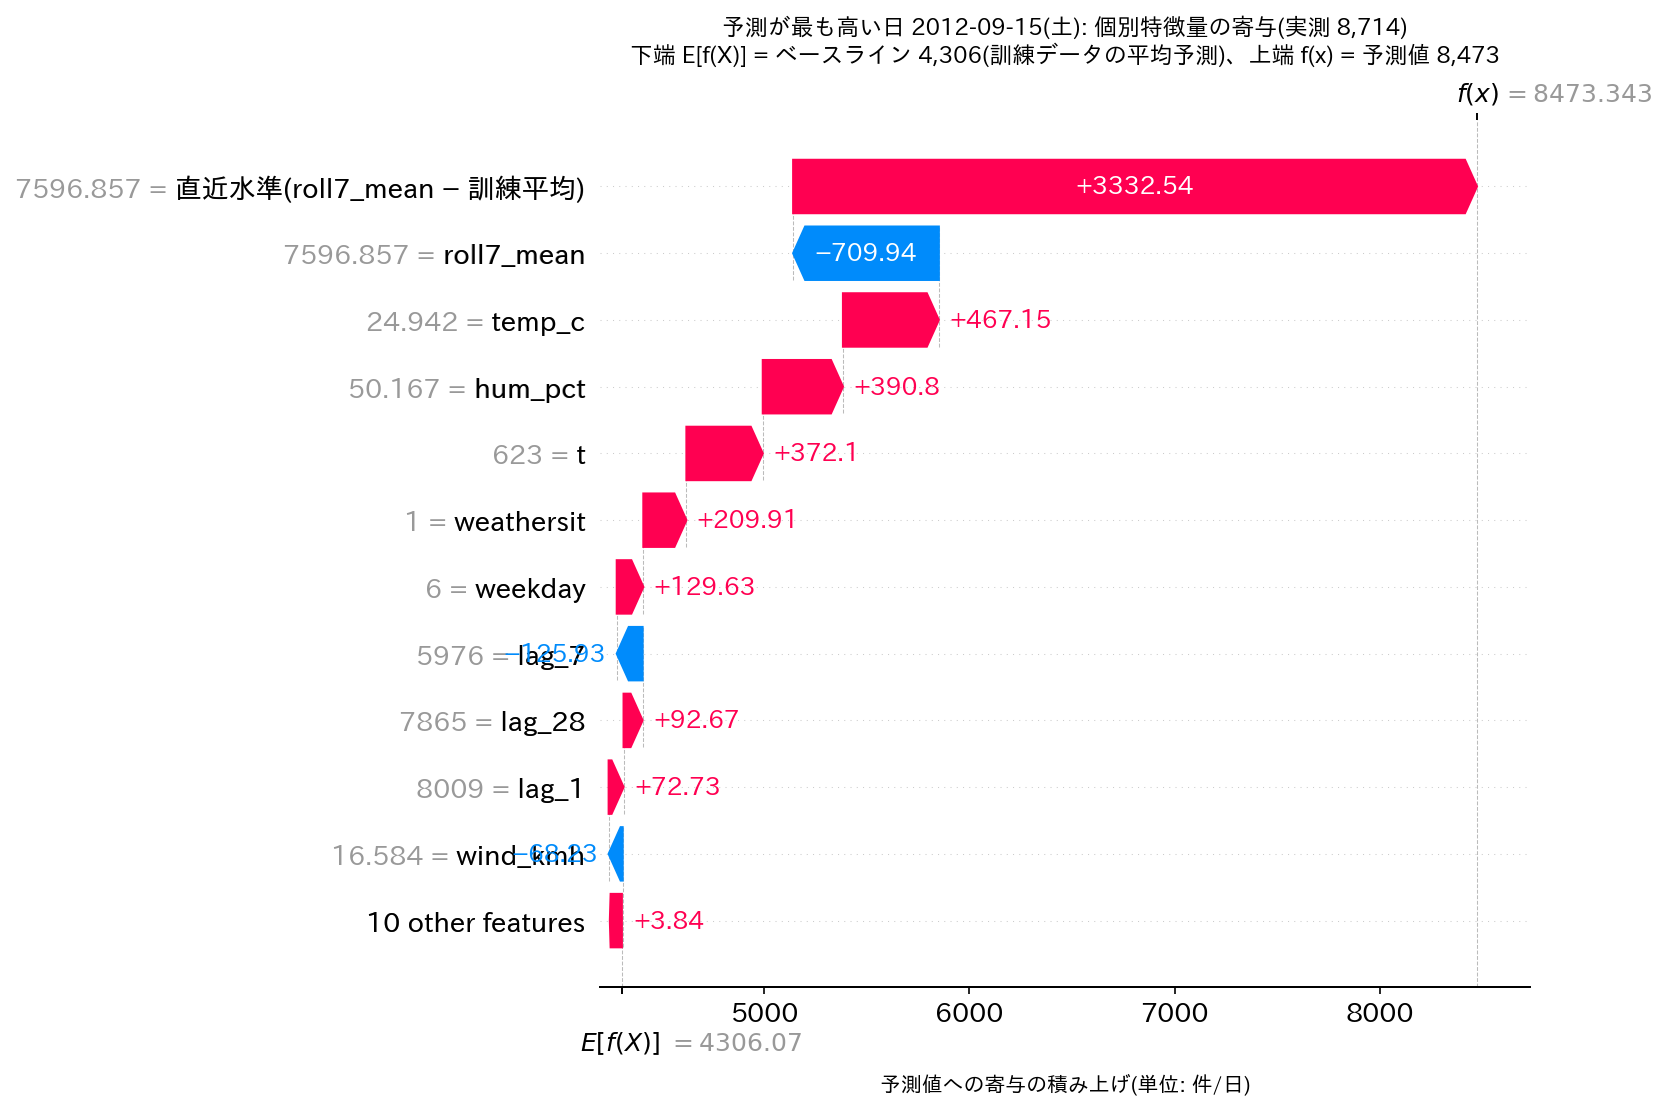

■ group_waterfall_day1.png  [生成I/F: xai_platform._core.plots.steps_waterfall]


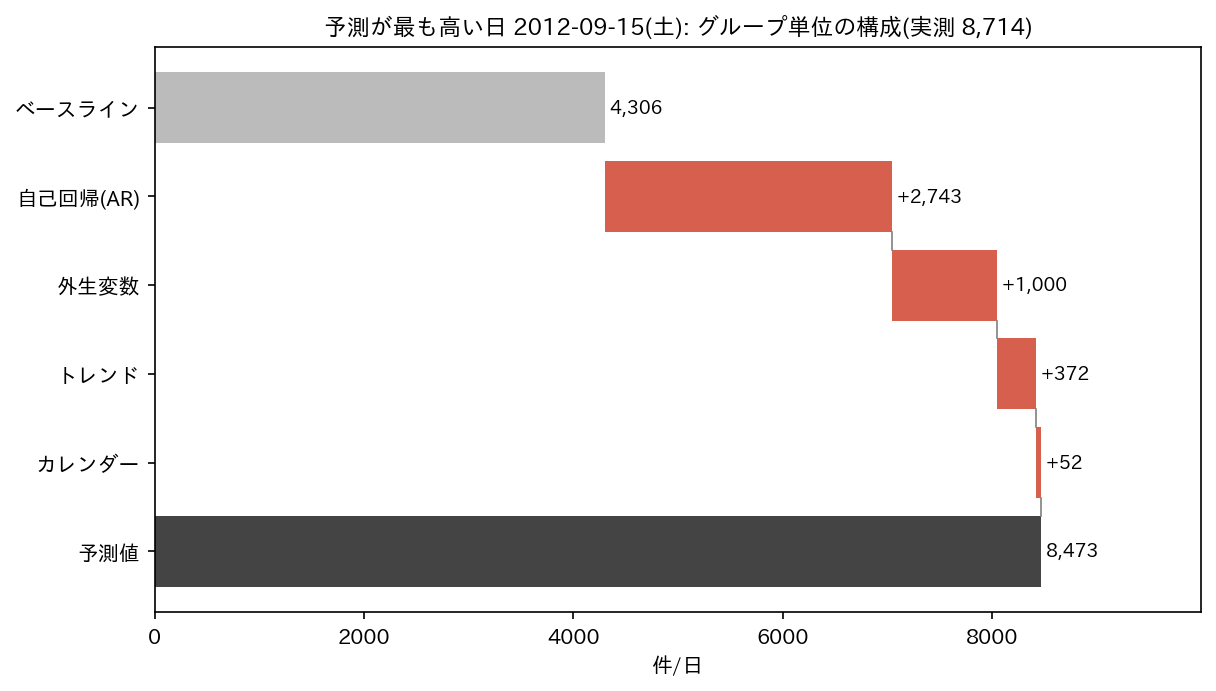

■ waterfall_day2.png  [生成I/F: xai_platform._core.plots.waterfall]


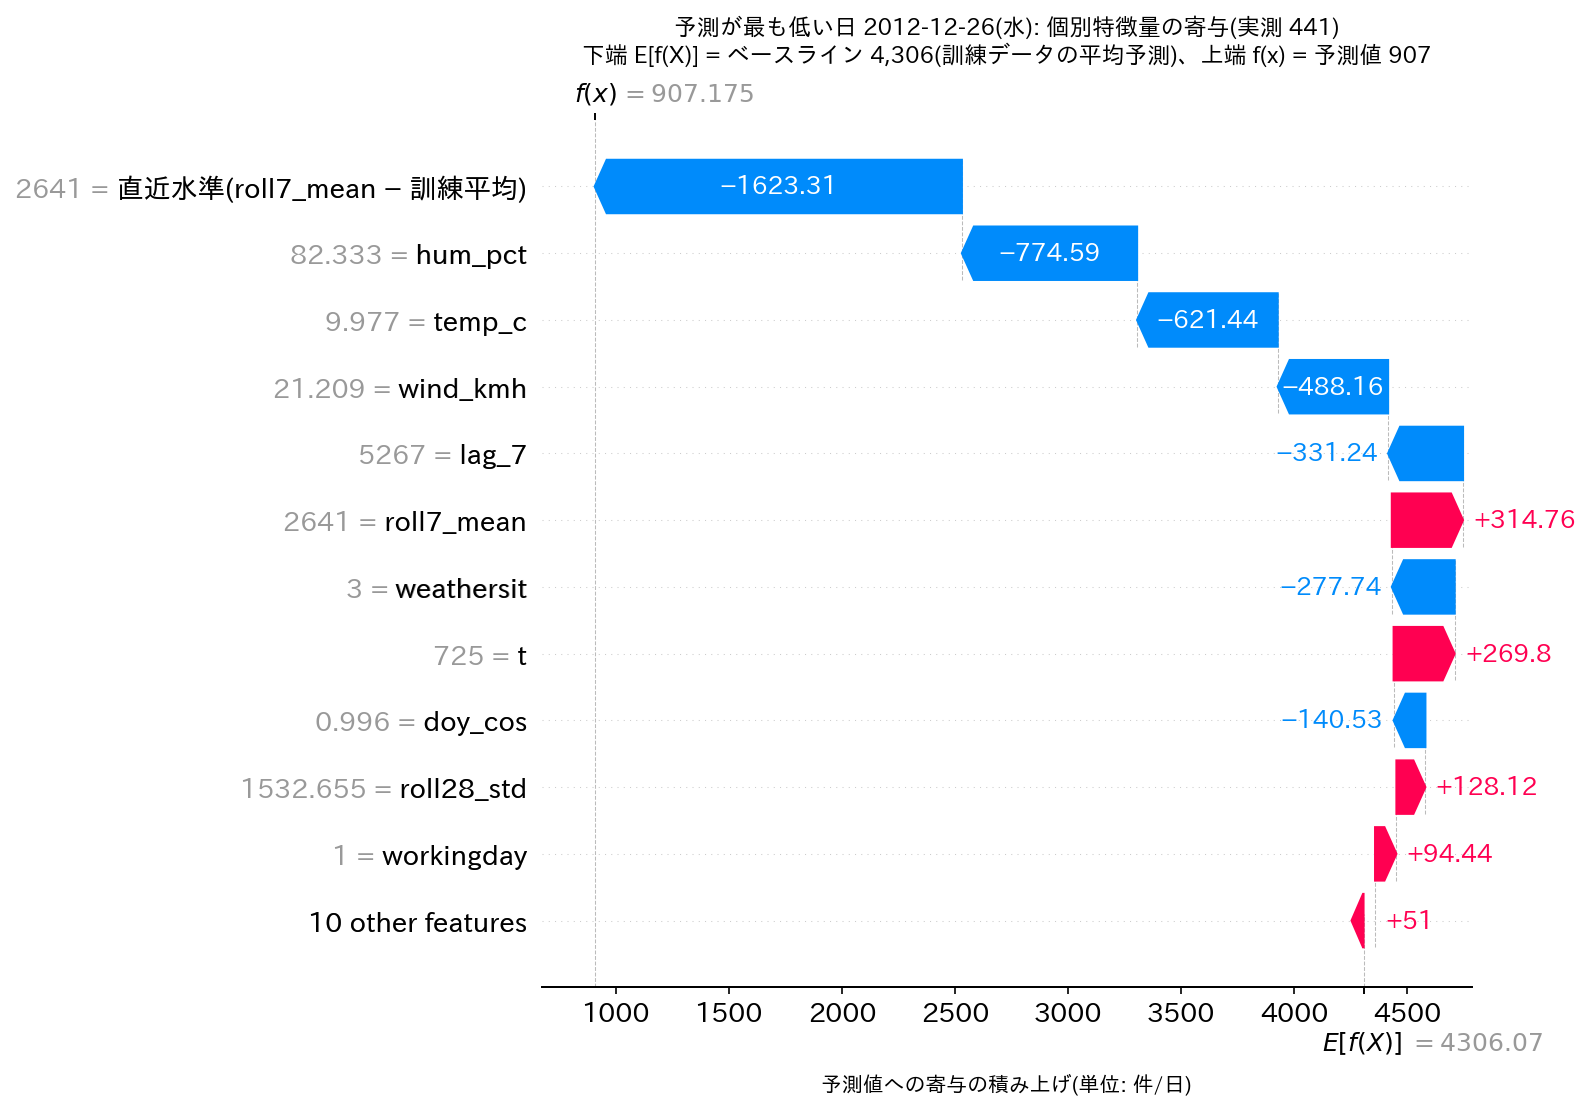

■ group_waterfall_day2.png  [生成I/F: xai_platform._core.plots.steps_waterfall]


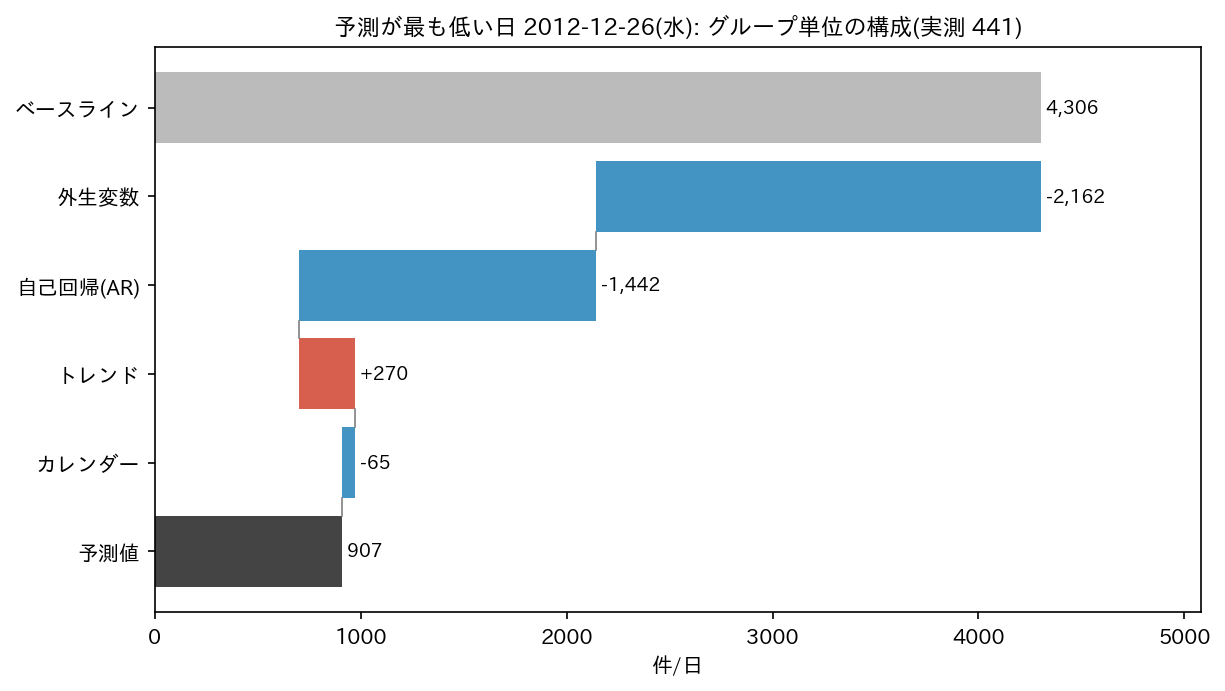

■ waterfall_day3.png  [生成I/F: xai_platform._core.plots.waterfall]


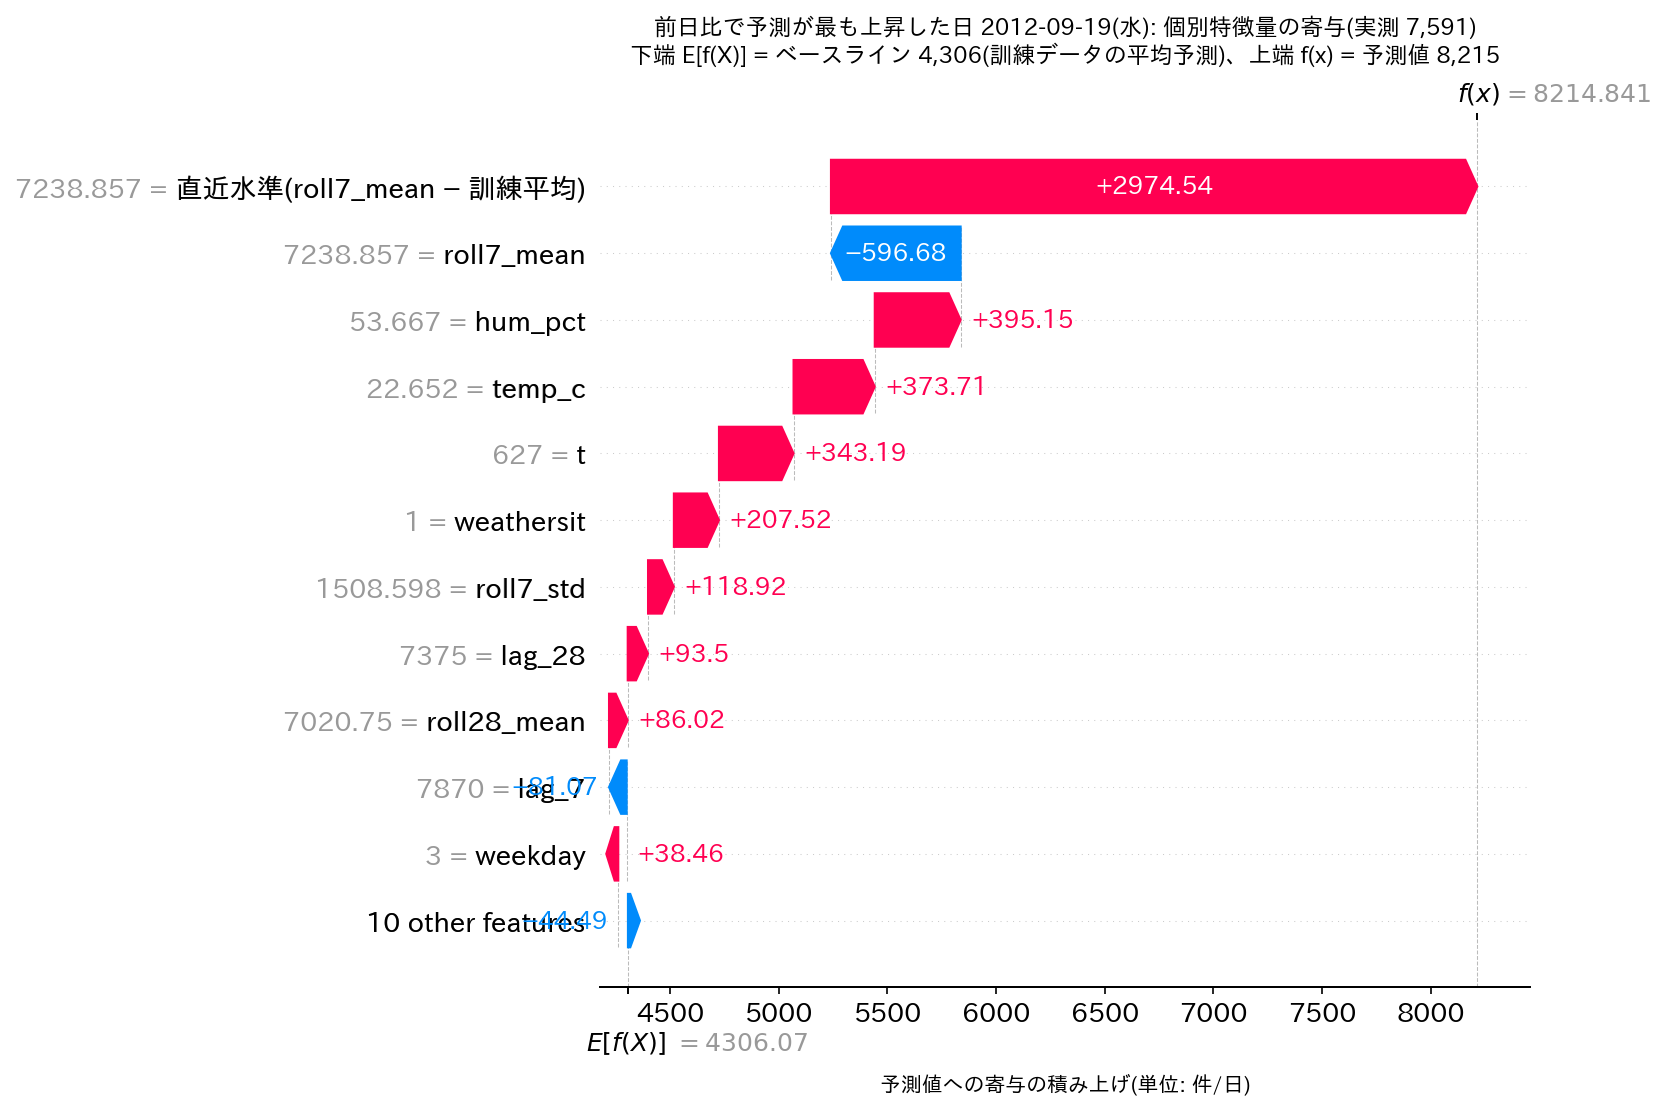

■ group_waterfall_day3.png  [生成I/F: xai_platform._core.plots.steps_waterfall]


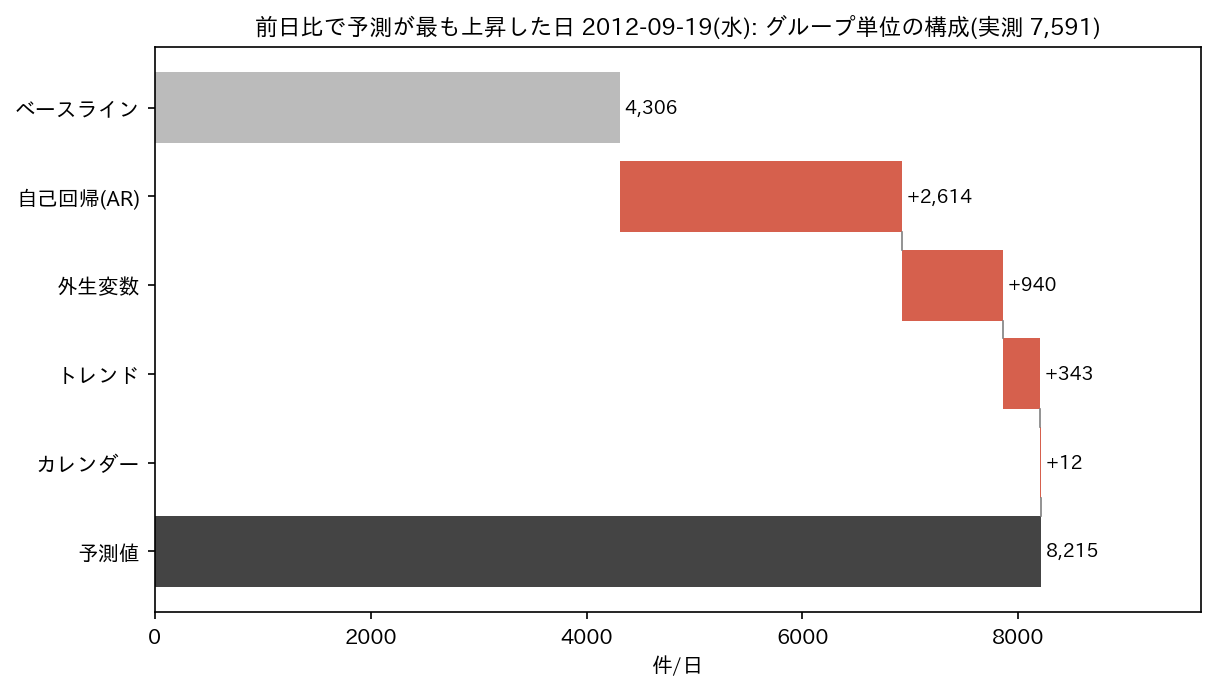

■ waterfall_day4.png  [生成I/F: xai_platform._core.plots.waterfall]


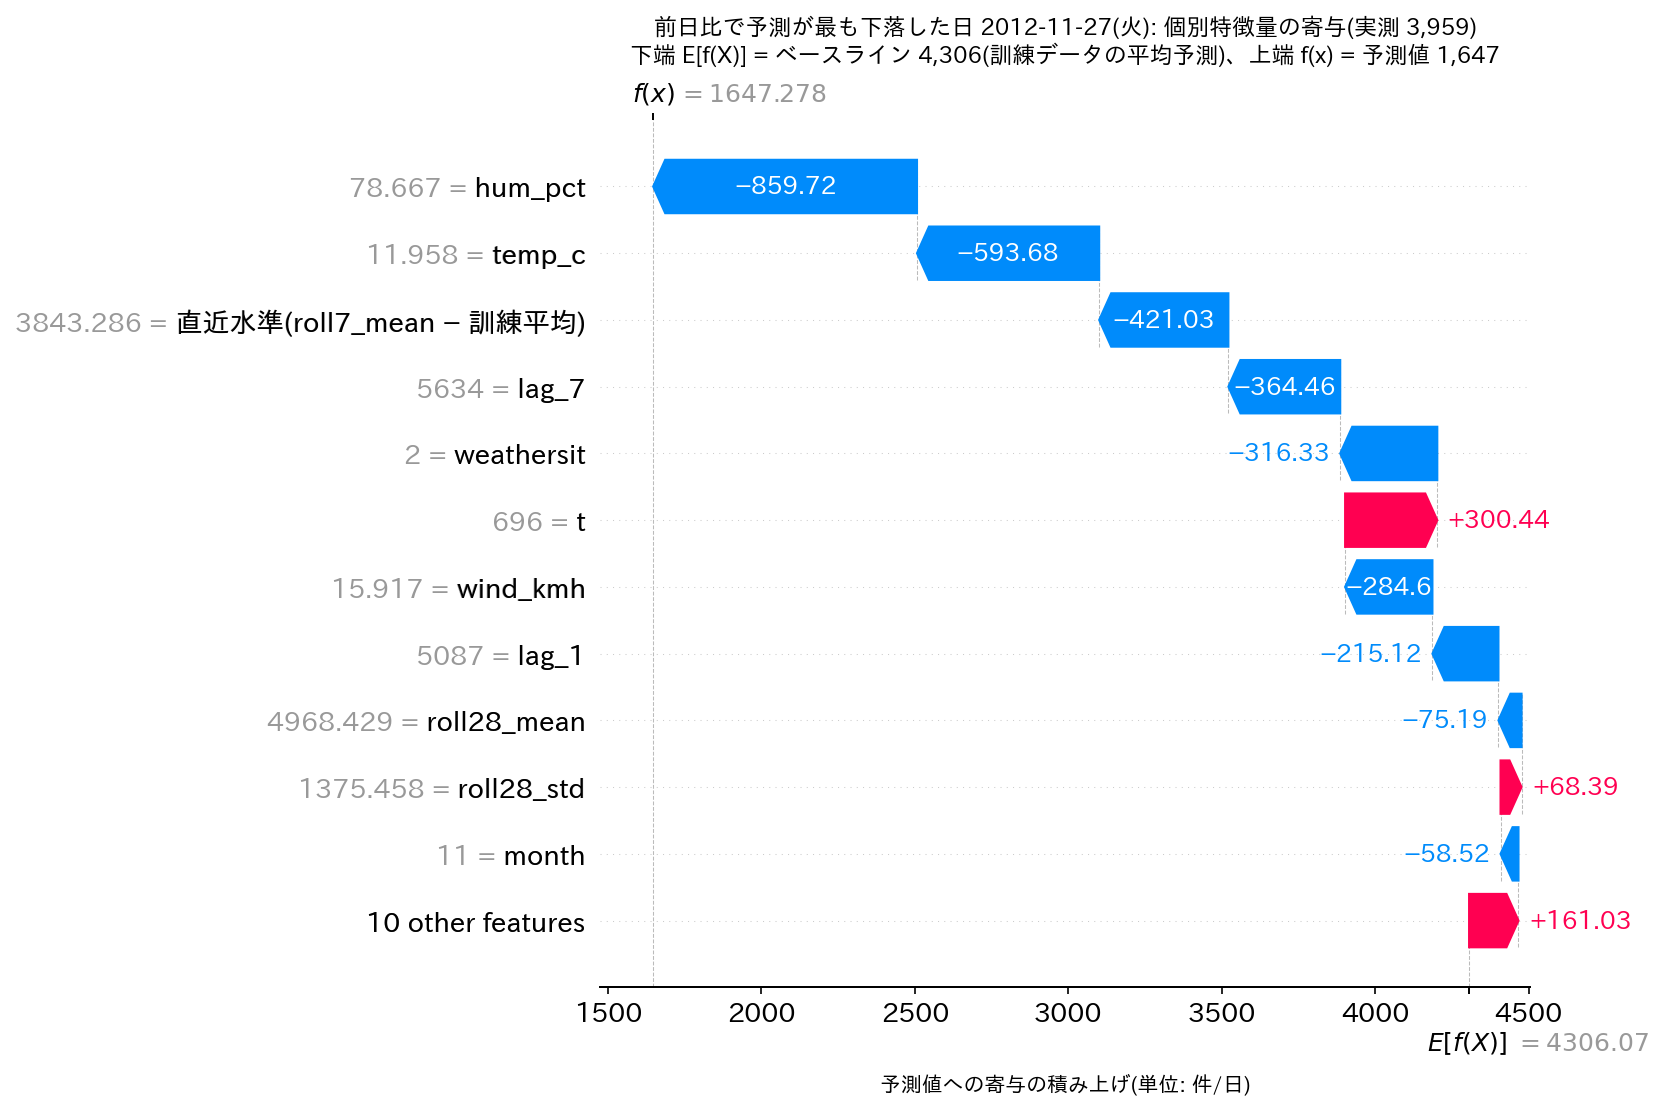

■ group_waterfall_day4.png  [生成I/F: xai_platform._core.plots.steps_waterfall]


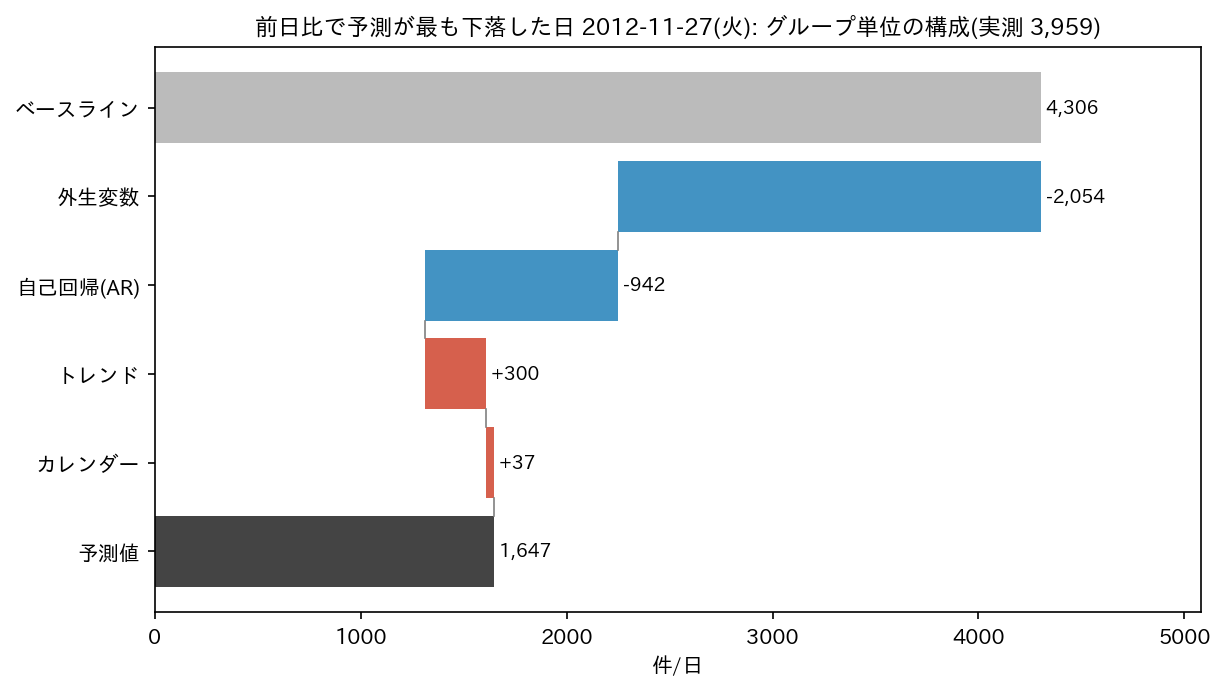

■ waterfall_day5.png  [生成I/F: xai_platform._core.plots.waterfall]


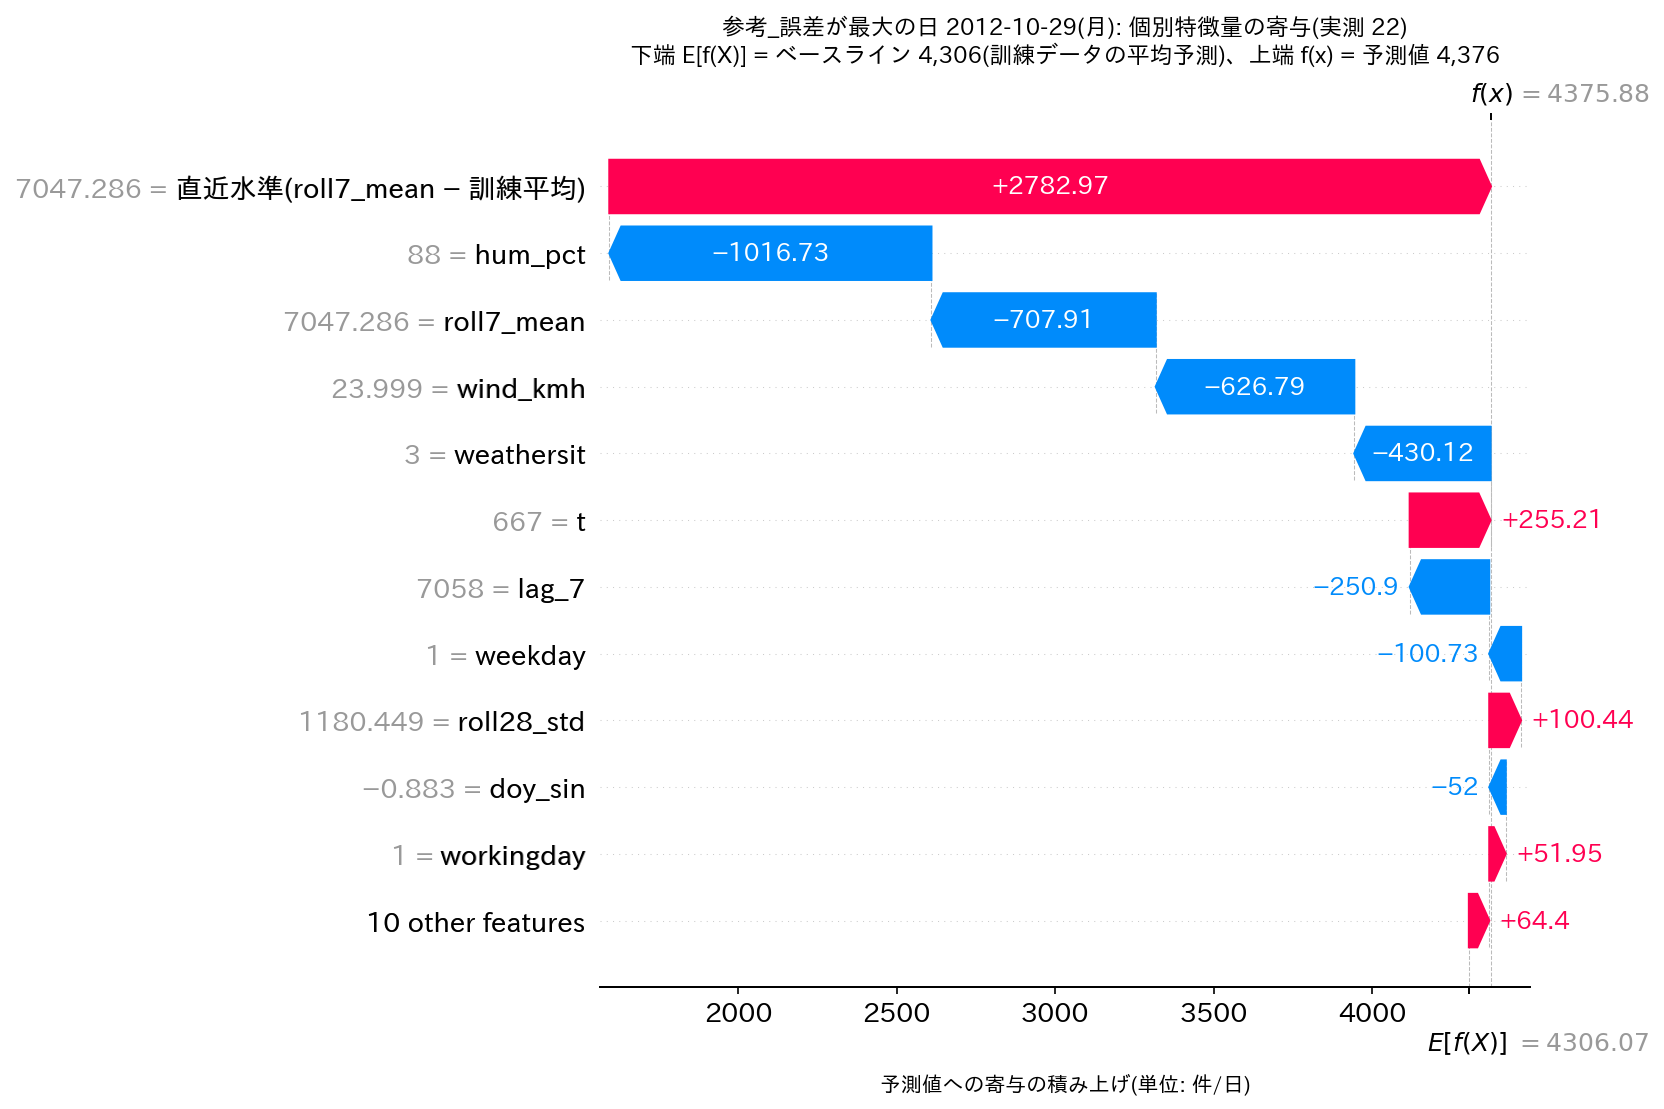

■ group_waterfall_day5.png  [生成I/F: xai_platform._core.plots.steps_waterfall]


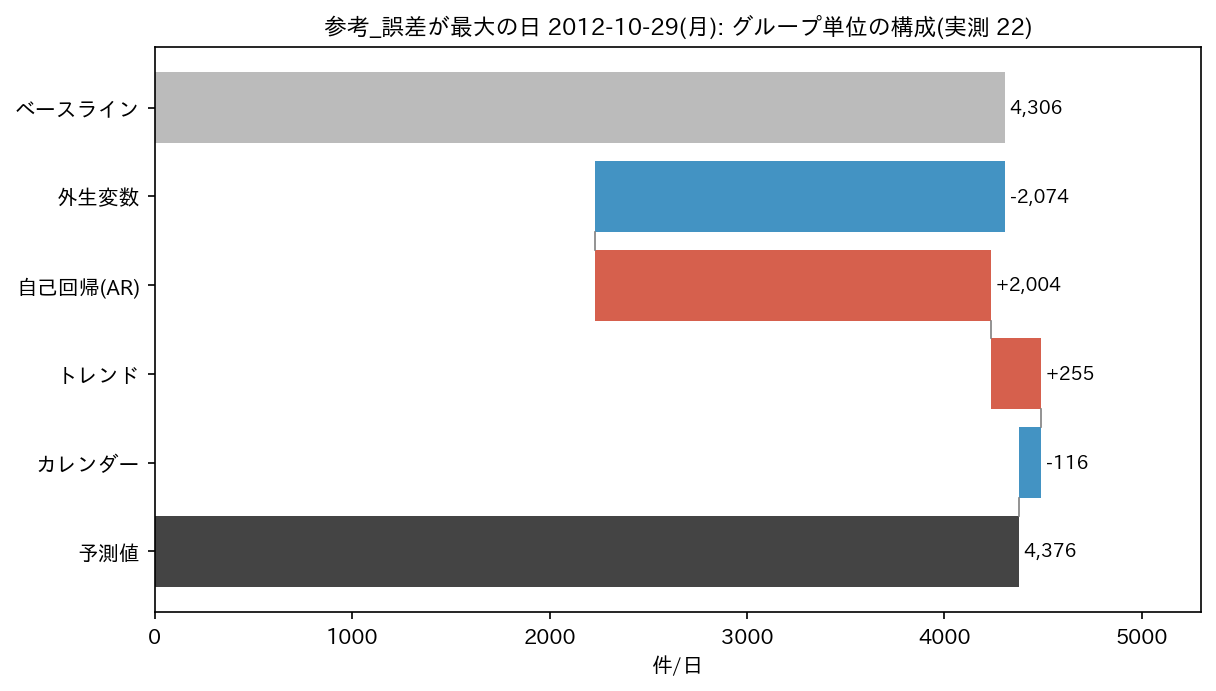

In [5]:
a.step_micro().show()

## 5. 時間方向の構成(マクロ)
訓練期間の寄与は学習データ上の説明(in-sample)である点に注意。

依存プロットの色(相互作用の強い特徴量): temp_c→hum_pct, hum_pct→t, wind_kmh→hum_pct, weathersit→直近水準(roll7_mean − 訓練平均)
■ 季節別の平均寄与(全期間)  [生成I/F: xai_platform._core.decompose.profile_means]


,自己回帰(AR),カレンダー,トレンド,外生変数,件数
季節,,,,,
春,92.571650,21.345583,31.373073,56.390596,184
夏,995.853224,-10.953010,99.549709,305.988385,184
秋,692.510940,-18.274242,134.971362,28.728386,182
冬,-929.595177,42.076015,65.322088,-423.244341,153


■ 月別の平均寄与(全期間)  [生成I/F: xai_platform._core.decompose.profile_means]


,自己回帰(AR),カレンダー,トレンド,外生変数,件数
月,,,,,
1,-1130.957110,163.335588,48.093804,-468.296968,34
2,-1306.197971,33.739527,-9.775770,-359.114885,57
3,-547.755494,62.058282,37.629128,-178.605632,62
4,65.467808,16.455764,17.670880,67.750520,60
5,759.128320,-14.635033,38.377204,280.393350,62
6,998.431725,9.793290,8.768424,461.216549,60
7,1008.403103,-14.757115,123.780172,123.310896,62
8,980.808023,-27.225970,163.172103,338.445068,62
9,1161.328496,-11.978310,146.971442,217.279361,60


■ 曜日別の平均寄与(全期間)  [生成I/F: xai_platform._core.decompose.profile_means]


,自己回帰(AR),カレンダー,トレンド,外生変数,件数
曜日,,,,,
日,239.974739,-143.431357,77.268503,2.458009,101
月,256.926050,-104.005003,82.302090,3.238551,101
火,270.096153,48.373776,79.996712,-29.220694,100
水,272.937387,47.162065,87.045599,-9.593379,100
木,281.650359,63.169960,87.442575,75.877563,100
金,270.706295,75.596580,89.106938,65.998515,100
土,241.119871,65.195900,80.921256,-36.946915,101


... (11 outputs left out)

,値の範囲,平均SHAP値,件数
0,1.499 – 7.188,302.051548,88
1,7.188 – 9.021,213.012789,88
2,9.021 – 10.47,117.042438,88
3,10.47 – 12.12,20.166473,88
4,12.12 – 13.88,17.170939,88
5,13.88 – 15.62,-65.427907,87
6,15.62 – 18.94,-117.294741,88
7,18.94 – 34,-349.871750,88


■ weathersit の値の範囲ごとの平均寄与  [生成I/F: xai_platform._core.explain.dependence_table]


,値の範囲,平均SHAP値,件数
0,0.999 – 2,-5.020918,683
1,2 – 3,-342.043723,20


■ stacked_contributions.png  [生成I/F: xai_platform._core.plots.stacked_contributions]


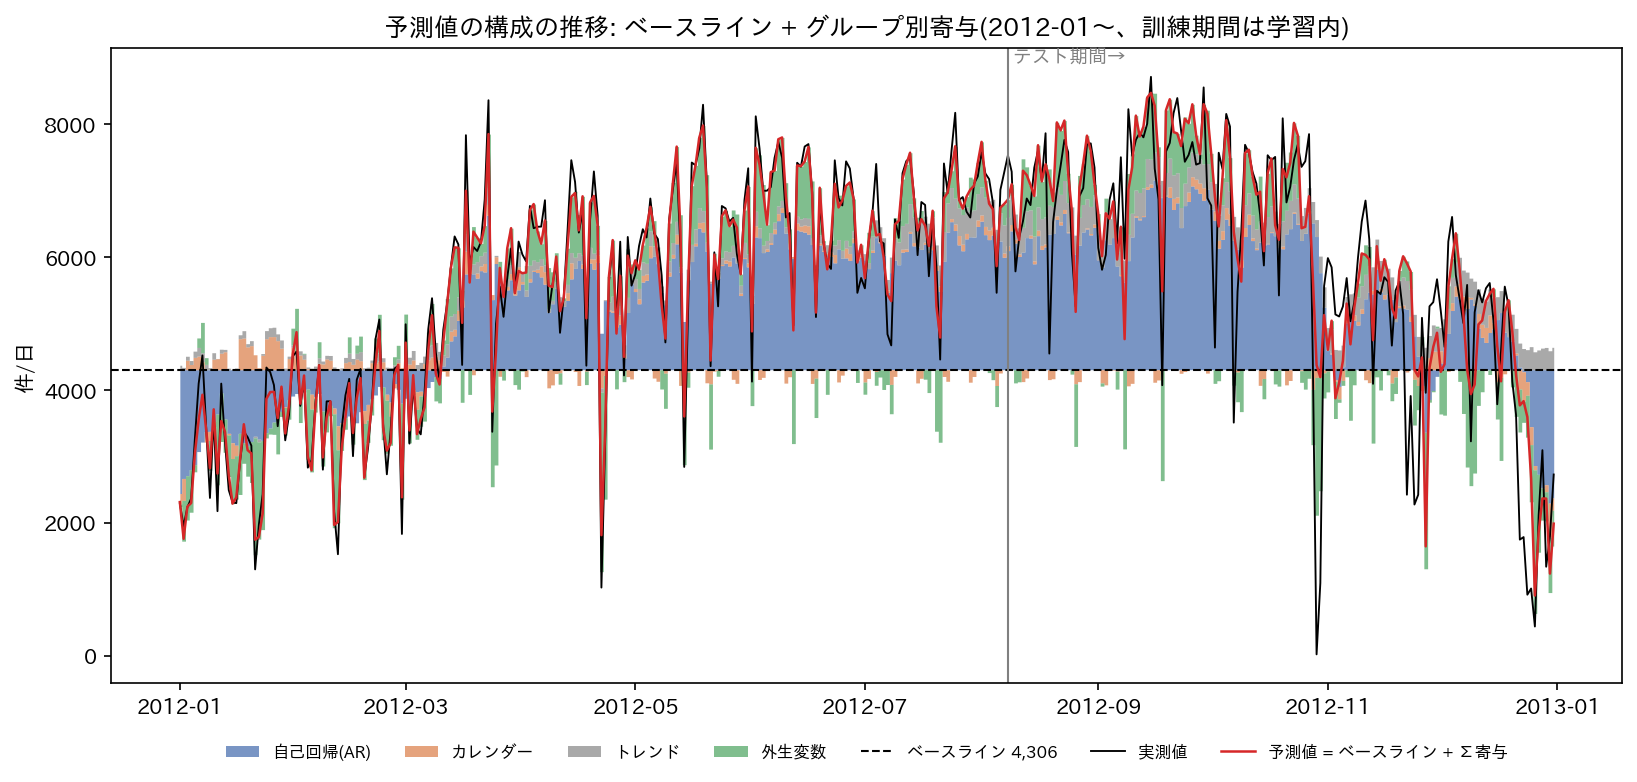

■ stacked_contributions_test.png  [生成I/F: xai_platform._core.plots.stacked_contributions]


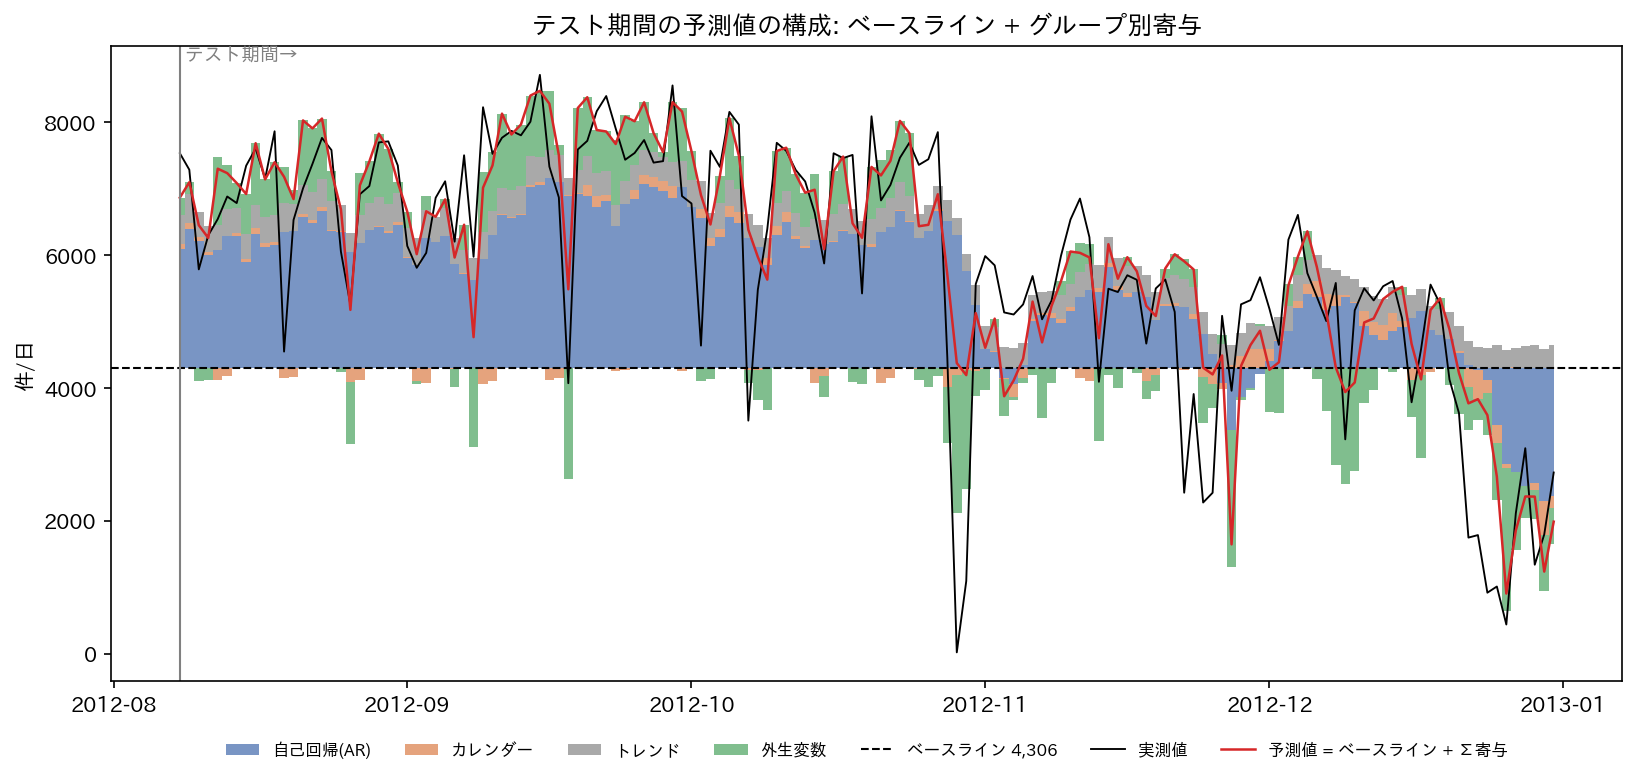

■ profile_month.png  [生成I/F: xai_platform._core.plots.profile_heatmap]


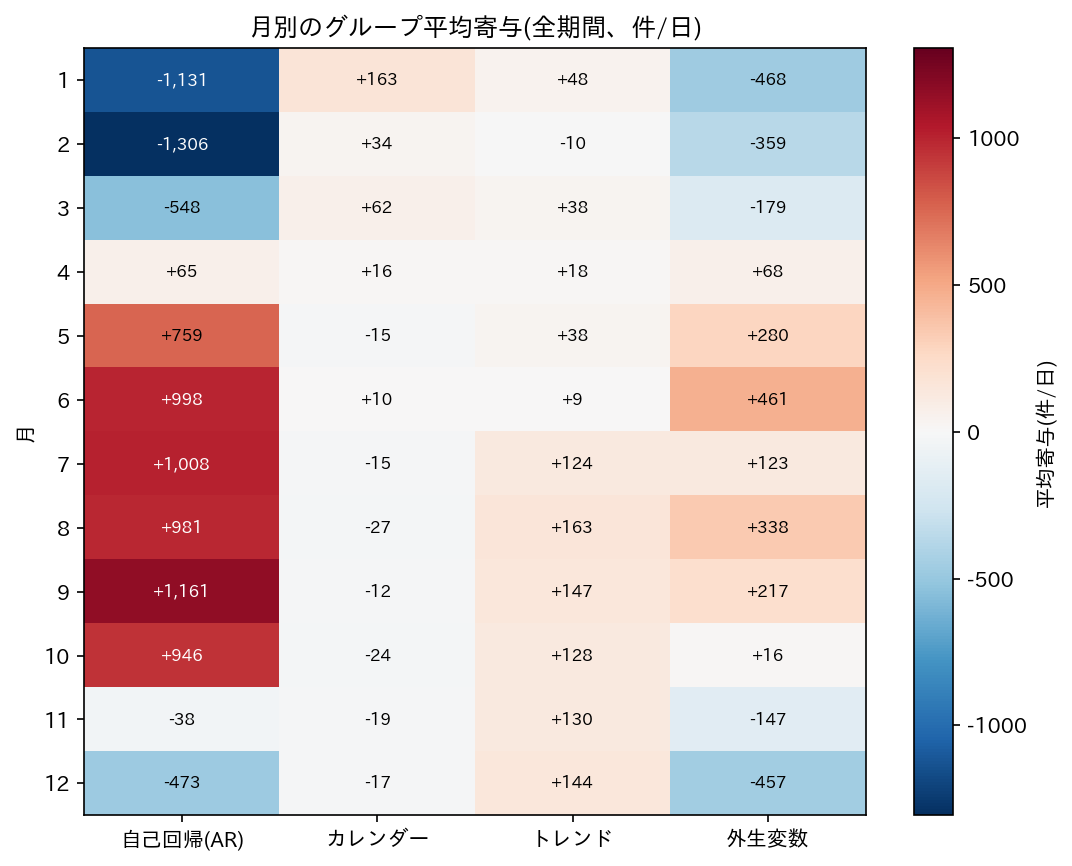

■ profile_weekday.png  [生成I/F: xai_platform._core.plots.profile_heatmap]


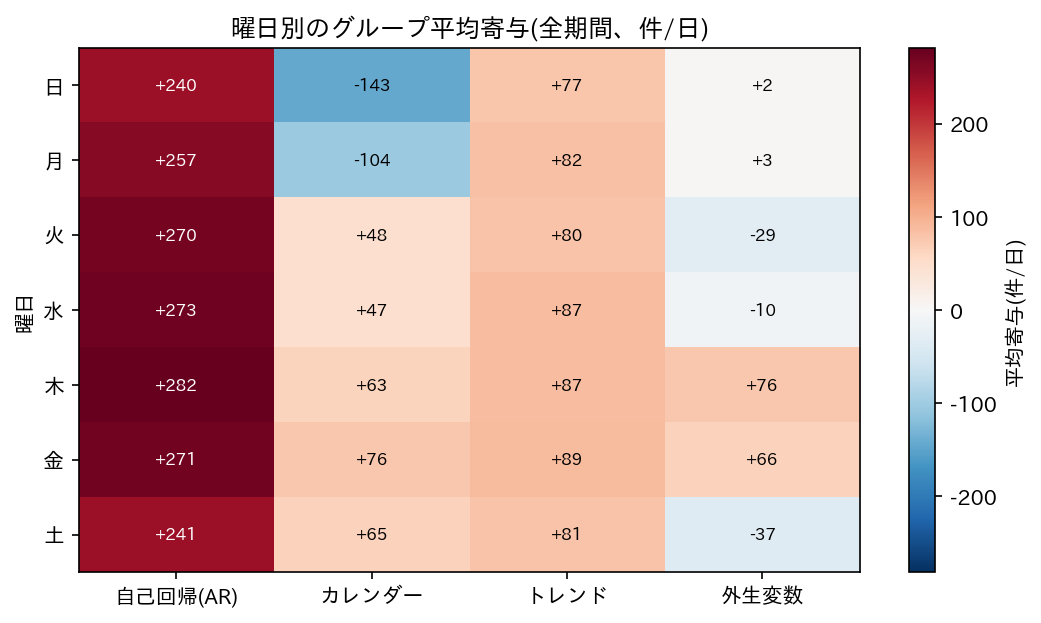

■ stl_comparison.png  [生成I/F: plots.stl_comparison]


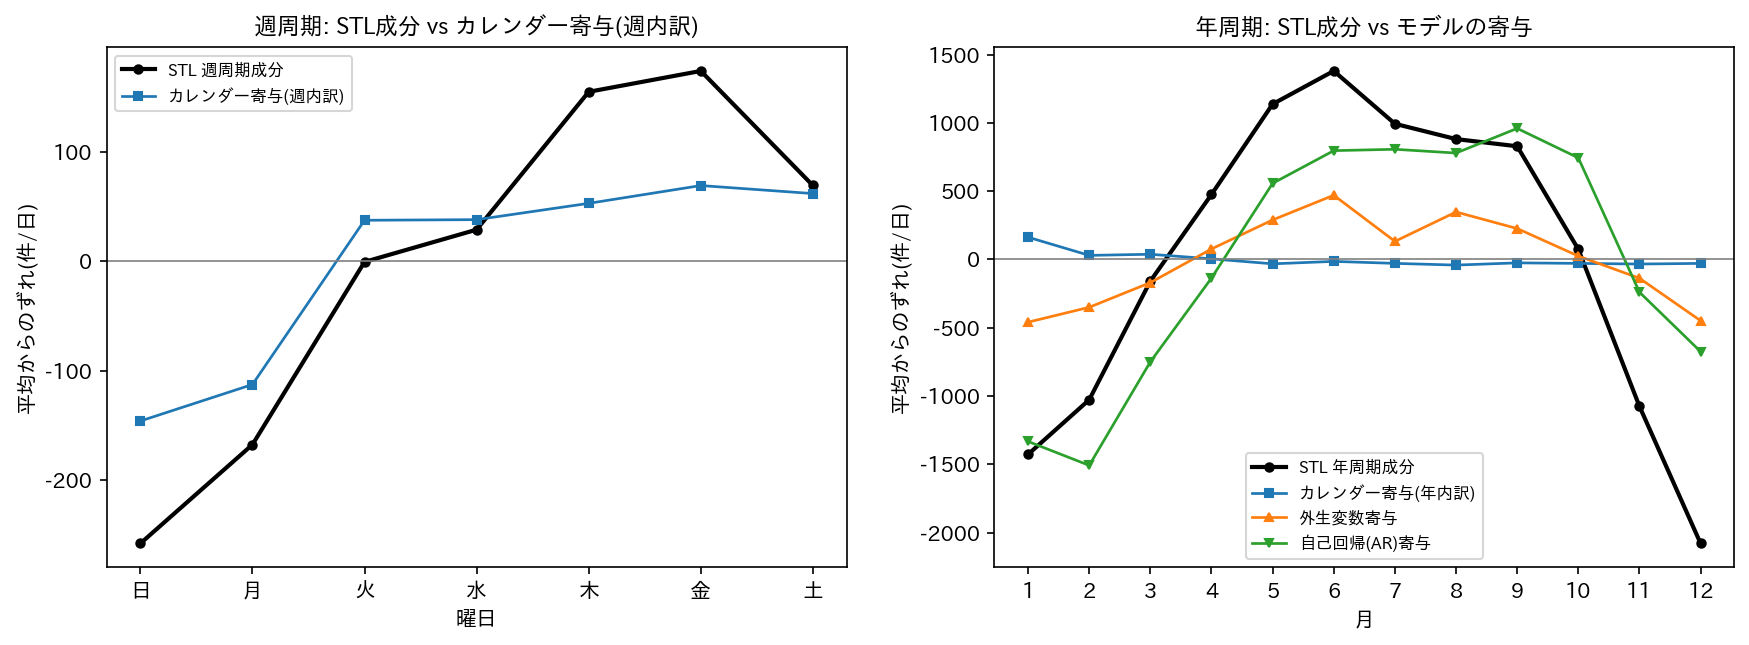

■ beeswarm_test.png  [生成I/F: xai_platform._core.plots.beeswarm]


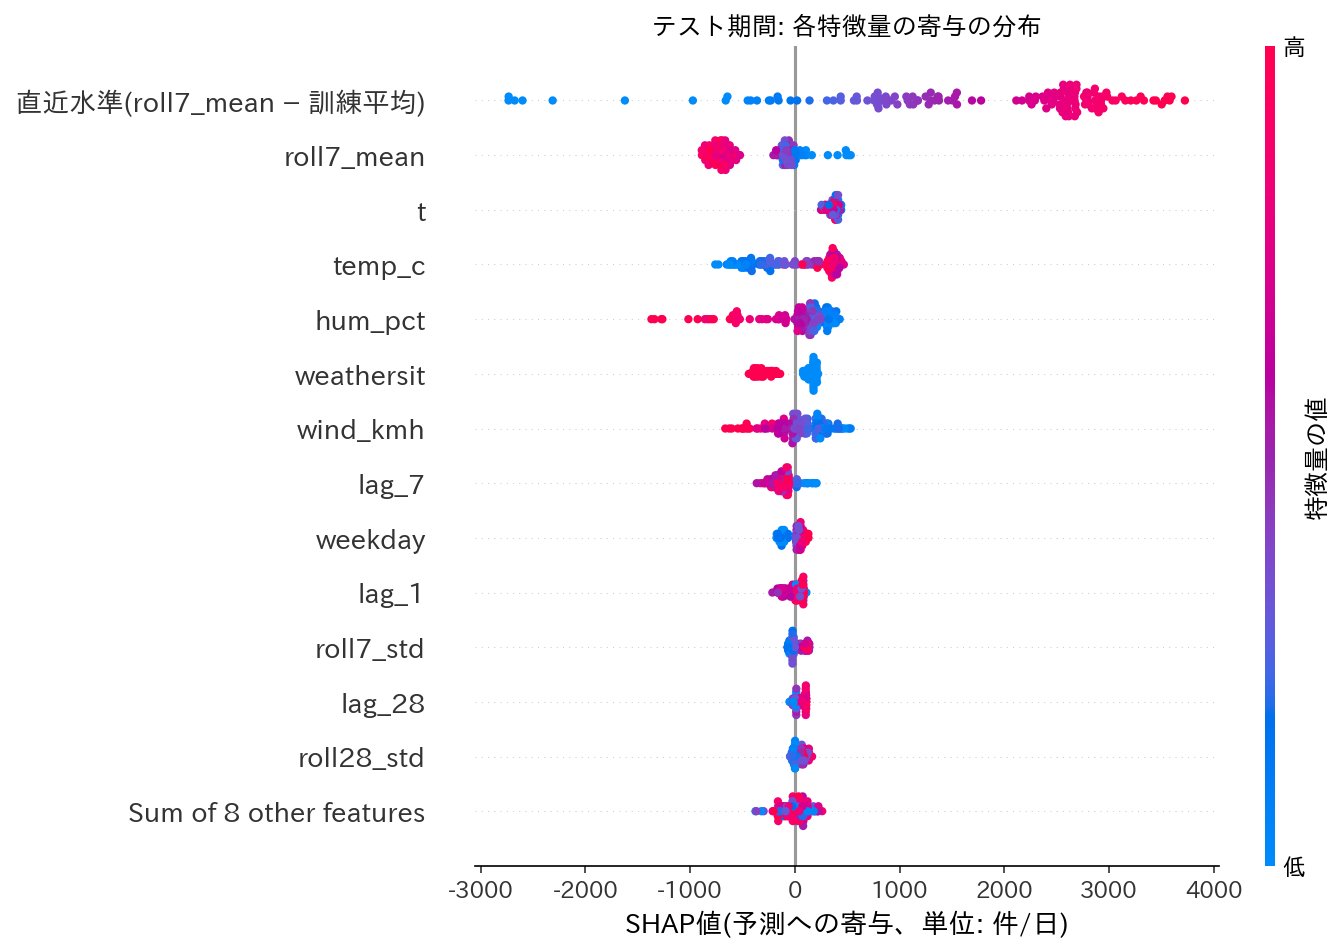

■ mean_abs_test.png  [生成I/F: xai_platform._core.plots.mean_abs_bar]


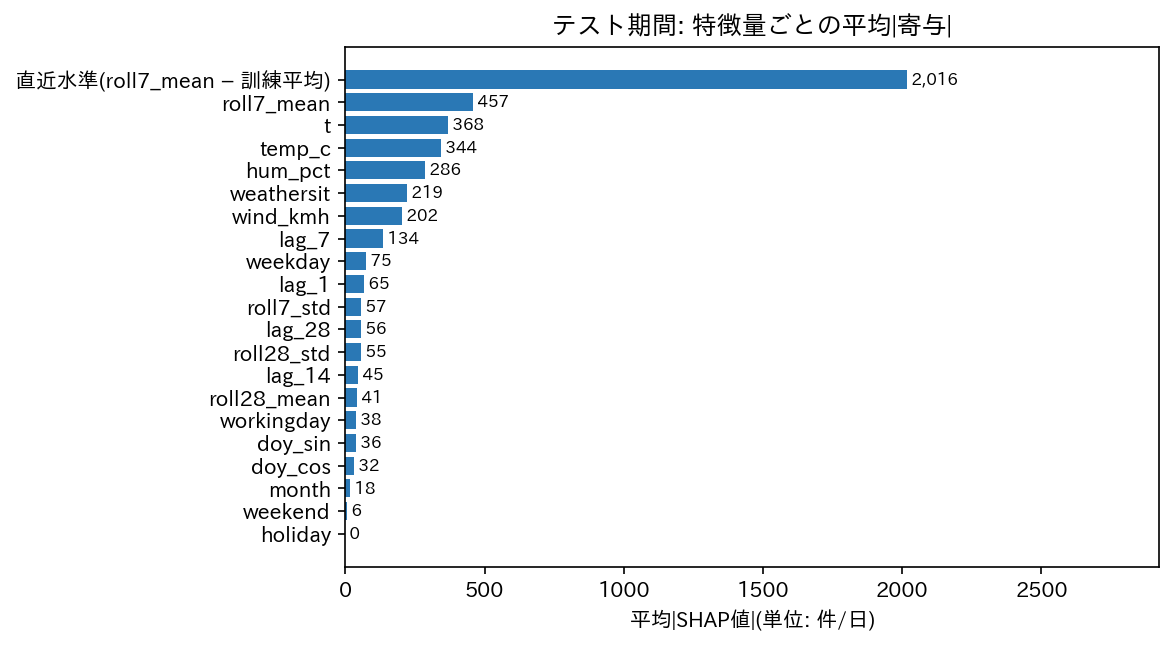

■ dependence_temp_c.png  [生成I/F: xai_platform._core.plots.dependence]


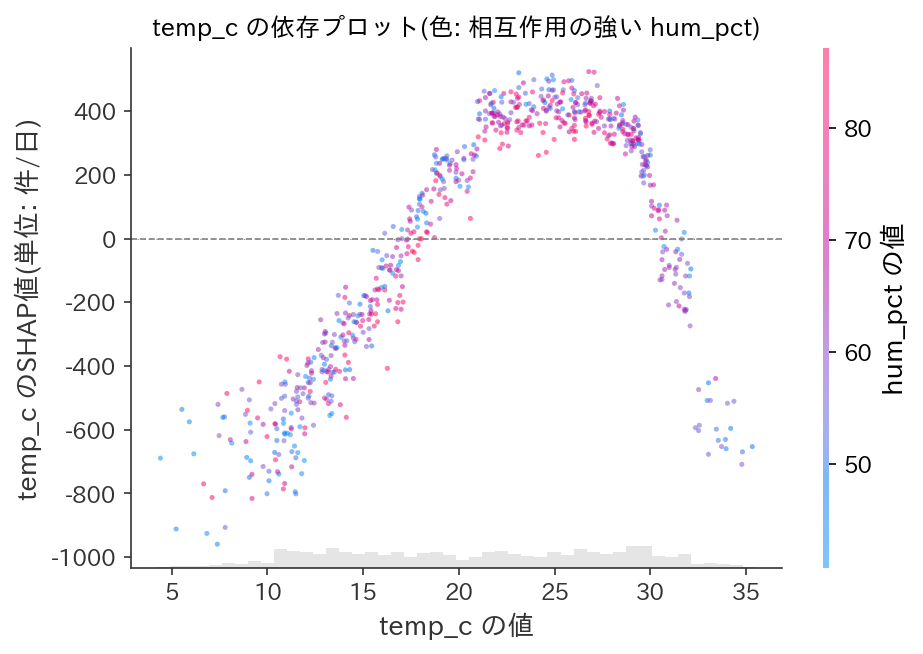

■ dependence_hum_pct.png  [生成I/F: xai_platform._core.plots.dependence]


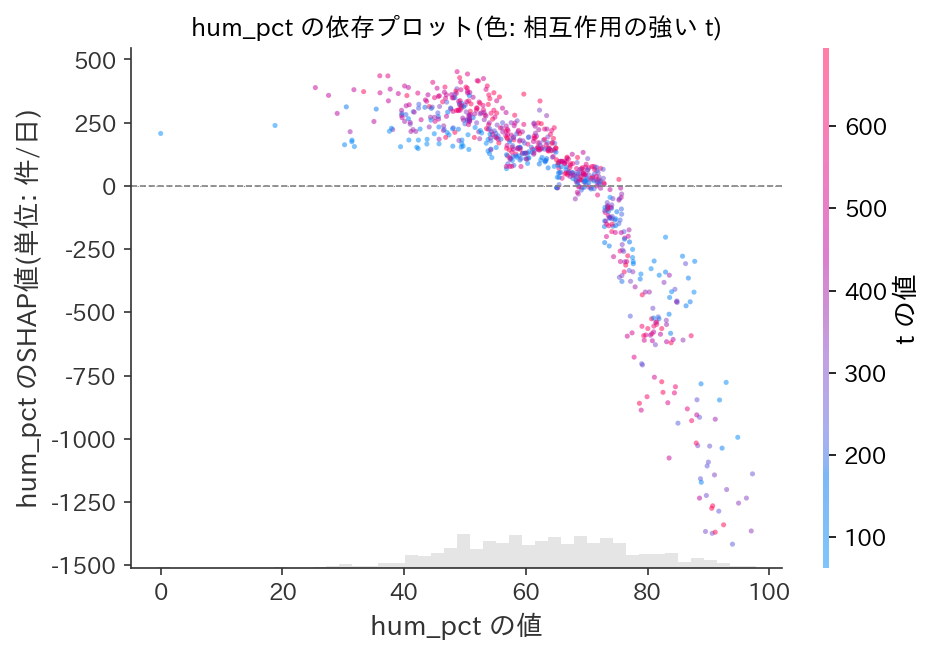

■ dependence_wind_kmh.png  [生成I/F: xai_platform._core.plots.dependence]


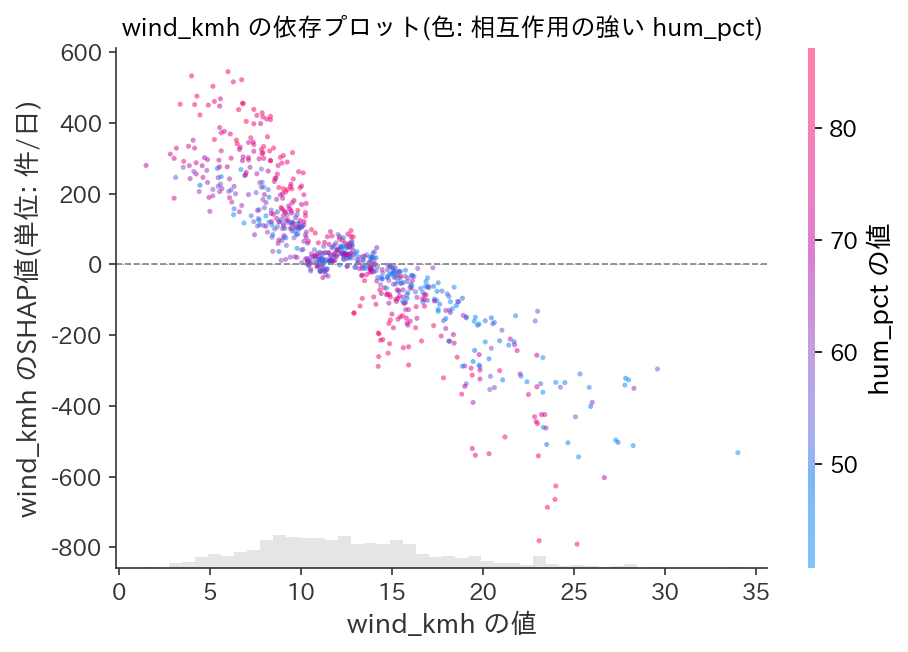

■ dependence_weathersit.png  [生成I/F: xai_platform._core.plots.dependence]


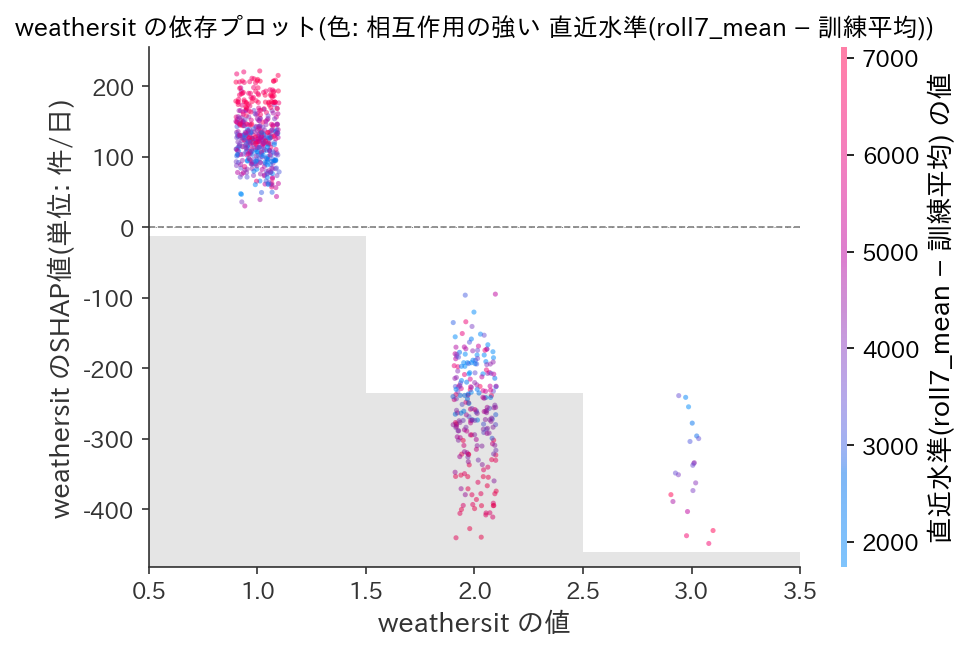

In [6]:
a.step_macro().show()

## 6. 変化の要因分解(ΔSHAP)
予測値(t) − 予測値(s) = Σ_グループ[寄与(t) − 寄与(s)]。ベースラインは共通なので差で消える。

■ 比較時点ごとの平均Δ(テスト期間)


,Δ予測値,Δ自己回帰(AR),Δカレンダー,Δトレンド,Δ外生変数,Δ実測値,恒等式の誤差
比較(テスト期間の平均。恒等式の誤差は最大値),,,,,,,
前日比,-32.961527,-24.794152,-1.723741,-0.590021,-5.853612,-31.123288,9.094947e-12
前週同曜日比,-235.892550,-170.972601,-9.458206,-5.044392,-50.417351,-246.993151,9.094947e-12
前年同期比(52週前・同曜日),2323.365974,1714.713435,39.045080,451.441640,118.165819,2174.541096,8.640200e-12


■ 前日比の上昇・下落 上位10日  [生成I/F: decompose.top_change_drivers]


,曜日付き,比較日,予測値(比較日),予測値(当日),Δ予測値,Δ自己回帰(AR),Δカレンダー,Δトレンド,Δ外生変数,ΣΔ寄与,Δ実測値,恒等式の誤差,方向,主因グループ
日付,,,,,,,,,,,,,,
2012-09-19,2012-09-19(水),2012-09-18,5485.996035,8214.841477,2728.845442,22.951074,8.517008,87.850869,2609.526490,2728.845442,3518.0,5.456968e-12,上昇,外生変数
2012-11-28,2012-11-28(水),2012-11-27,1647.277689,4333.338986,2686.061297,493.962852,146.748621,31.439653,2013.910171,2686.061297,1301.0,0.000000e+00,上昇,外生変数
2012-09-09,2012-09-09(日),2012-09-08,4766.225907,7015.819385,2249.593478,320.864143,-247.621137,69.701131,2106.649341,2249.593478,2251.0,9.094947e-12,上昇,外生変数
2012-10-10,2012-10-10(水),2012-10-09,5632.041497,7567.903635,1935.862137,461.214861,30.827855,35.338342,1408.481079,1935.862137,1299.0,2.273737e-13,上昇,外生変数
2012-08-27,2012-08-27(月),2012-08-26,5176.802177,7051.029076,1874.226900,131.662967,32.402984,136.493858,1573.667091,1874.226900,1662.0,8.185452e-12,上昇,外生変数
2012-11-14,2012-11-14(水),2012-11-13,4750.379996,6165.232961,1414.852965,375.908833,7.471184,34.054451,997.418496,1414.852965,1401.0,6.821210e-13,上昇,外生変数
2012-08-21,2012-08-21(火),2012-08-20,6844.632545,8028.149388,1183.516843,211.416268,189.591338,34.708469,747.800769,1183.516843,476.0,1.364242e-12,上昇,外生変数
2012-10-16,2012-10-16(火),2012-10-15,6090.756425,7263.645377,1172.888952,25.206373,138.977176,52.000102,956.705301,1172.888952,1659.0,1.364242e-12,上昇,外生変数
2012-12-03,2012-12-03(月),2012-12-02,4388.222590,5544.290102,1156.067511,149.902078,-41.726719,23.717685,1024.174468,1156.067511,1585.0,2.501110e-12,上昇,外生変数


■ 主因グループの集計  [生成I/F: decompose.top_change_drivers]


,主因の件数:自己回帰(AR),主因の件数:カレンダー,主因の件数:トレンド,主因の件数:外生変数,平均Δ自己回帰(AR),平均Δカレンダー,平均Δトレンド,平均Δ外生変数,平均Δ予測値
方向,,,,,,,,,
上昇,0,0,0,10,217.345259,30.760212,52.397225,1446.377894,1746.880590
下落,0,0,0,10,-273.190491,9.139258,-64.516968,-1317.527696,-1646.095897


■ delta_lag1_up.png  [生成I/F: xai_platform._core.plots.steps_waterfall]


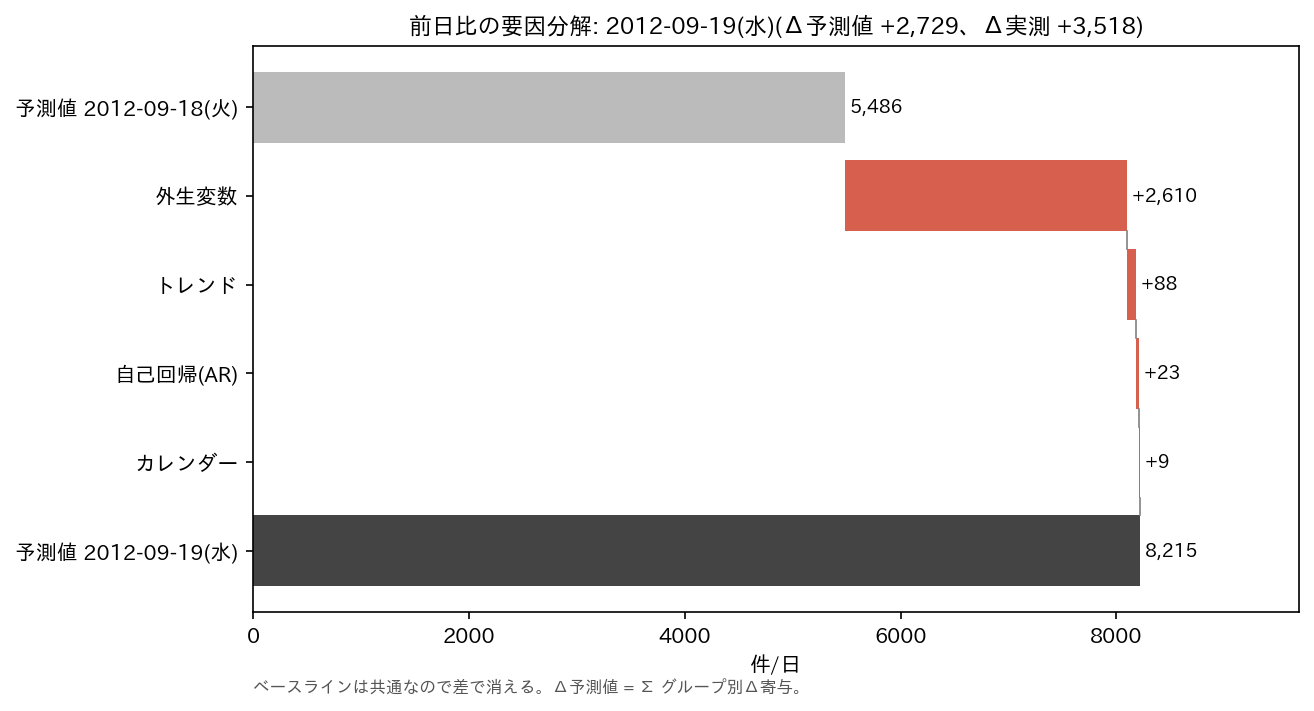

■ delta_lag1_down.png  [生成I/F: xai_platform._core.plots.steps_waterfall]


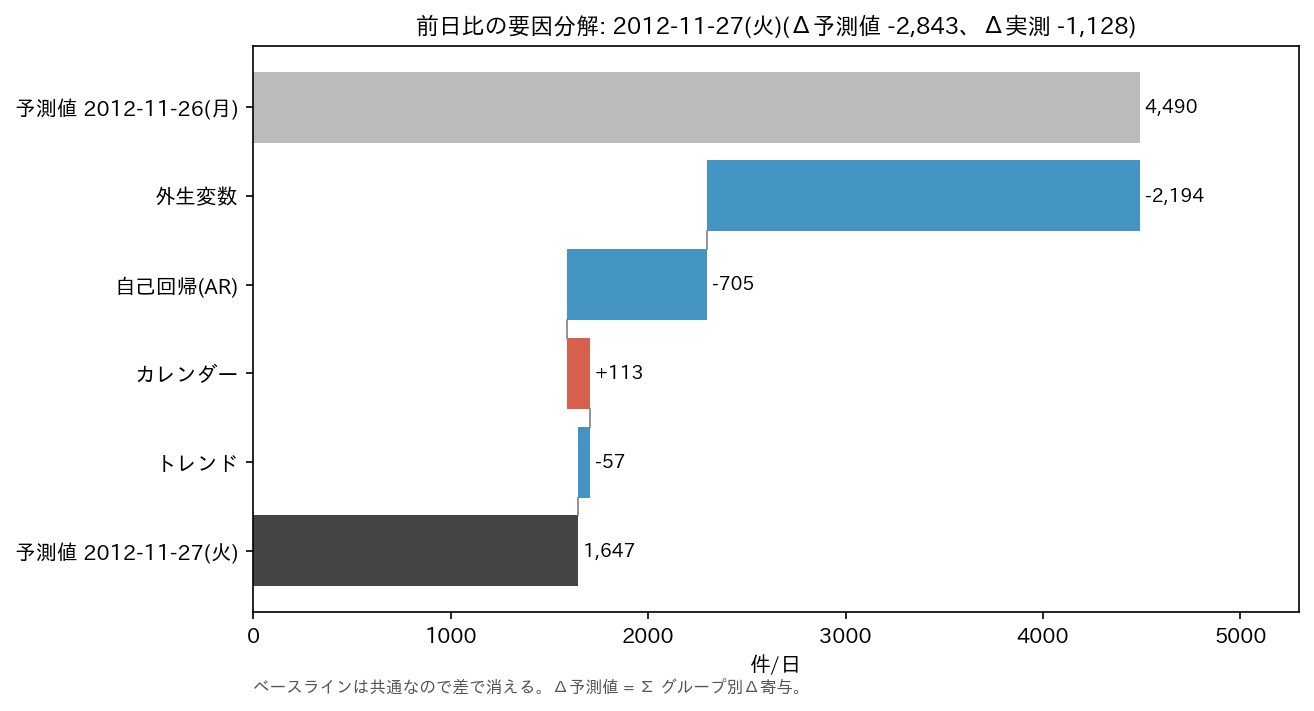

■ delta_lag7_top.png  [生成I/F: xai_platform._core.plots.steps_waterfall]


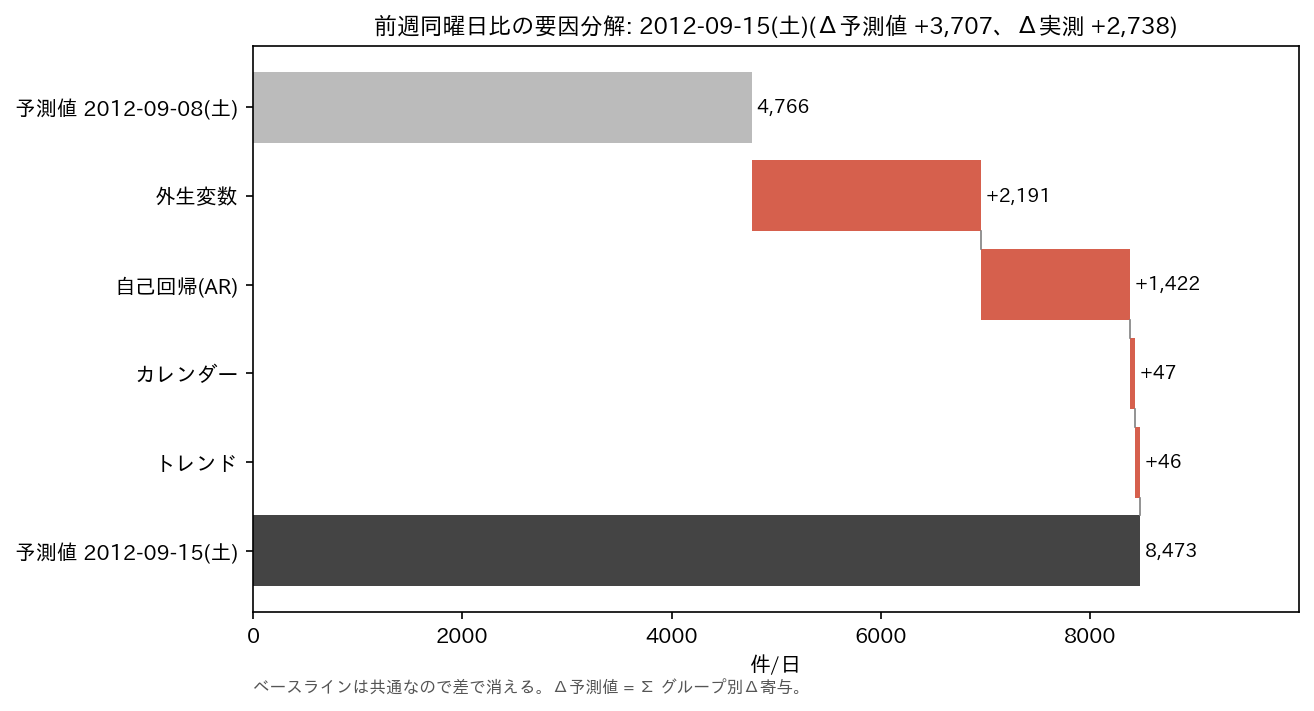

■ delta_lag364_top.png  [生成I/F: xai_platform._core.plots.steps_waterfall]


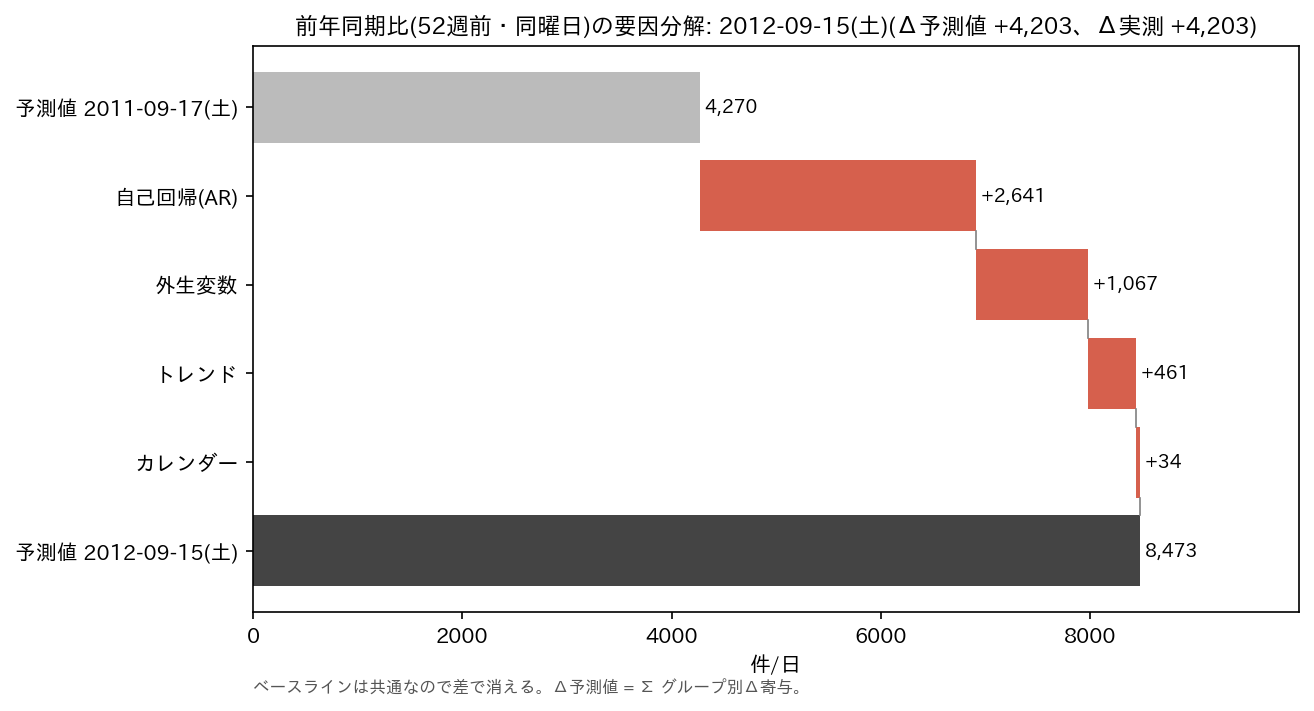

In [7]:
a.step_delta().show()

## 7. What-if(外生変数のみを動かす)
(A) Δ予測値はモデルの再予測、(B) 内訳は ΔSHAP。動かす範囲は訓練期間の 1〜99 パーセンタイル内に制限する(範囲外はクリップし、図表に警告を出す)。

■ 単独変更のΔ予測値(代表日)  [生成I/F: xai_platform._core.whatif.scenario_analysis]


,シナリオ,天候1段階悪化,風速+10km/h,気温+5℃,湿度−10pt
区分,日付,,,,
予測が最も高い日,2012-09-15,-842.845365,-466.269808,-272.984779,-8.340985
予測が最も低い日,2012-12-26,0.000000,-157.116046,93.086146,1078.417905
前日比で予測が最も上昇した日,2012-09-19,-831.398028,-276.206921,-16.493076,9.022181
前日比で予測が最も下落した日,2012-11-27,0.000000,-398.807052,244.193456,1340.612546
参考_誤差が最大の日,2012-10-29,0.000000,0.000000,443.297897,110.720245


■ 同時変更のΔ予測値と相互作用分(代表日)  [生成I/F: xai_platform._core.whatif.scenario_analysis]


Δ予測値(同時)                                   相互作用分(同時−単独合計)                                
シナリオ                      S1 気温+5℃×湿度−10pt S2 天候悪化×風速+10km/h S3 気温−5℃×天候悪化 S1 気温+5℃×湿度−10pt S2 天候悪化×風速+10km/h S3 気温−5℃×天候悪化
区分             日付                                                                                                          
予測が最も高い日       2012-09-15      -281.325764      -1340.985424  -1292.861966         0.000000        -31.870251   -112.512516
予測が最も低い日       2012-12-26      1284.423502       -157.116046    -36.660918       112.919451          0.000000      0.000000
前日比で予測が最も上昇した日 2012-09-19        -7.470895      -1139.475201  -1152.630884         0.000000        -31.870251     23.403998
前日比で予測が最も下落した日 2012-11-27      1671.038728       -398.807052    -27.528193        86.232727          0.000000      0.000000
参考_誤差が最大の日     2012-10-29       548.655720          0.000000   -590.145577        -5.362422          0.000000      0.000000

■ 期間全体への適用(テスト期間)  [生成I/F: xai_platform._core.whatif.period_analysis]


,日数,元の予測の合計,Δ予測値の合計,Δ予測値の合計(%),1日平均Δ,1日Δの最小,1日Δの最大,単独Δの合計の1日平均,相互作用分の1日平均,クリップした日数
シナリオ,,,,,,,,,,
P1 気温+2℃,146,883588.053822,5362.494879,0.606900,36.729417,-665.465865,505.788421,36.729417,0.000000,0
P2 気温+5℃×湿度−10pt,146,883588.053822,41113.539459,4.653021,281.599585,-1095.861862,1719.481074,294.431185,-12.831599,14


■ 月別の1日平均Δ  [生成I/F: xai_platform._core.whatif.period_analysis]


,P1 気温+2℃,P2 気温+5℃×湿度−10pt
月,,
2012-08,-288.835293,-574.888962
2012-09,-76.785540,-92.740224
2012-10,87.570358,432.445358
2012-11,213.755028,700.644526
2012-12,176.476652,750.578689


■ whatif_single_day1.png  [生成I/F: xai_platform._core.plots.tornado]


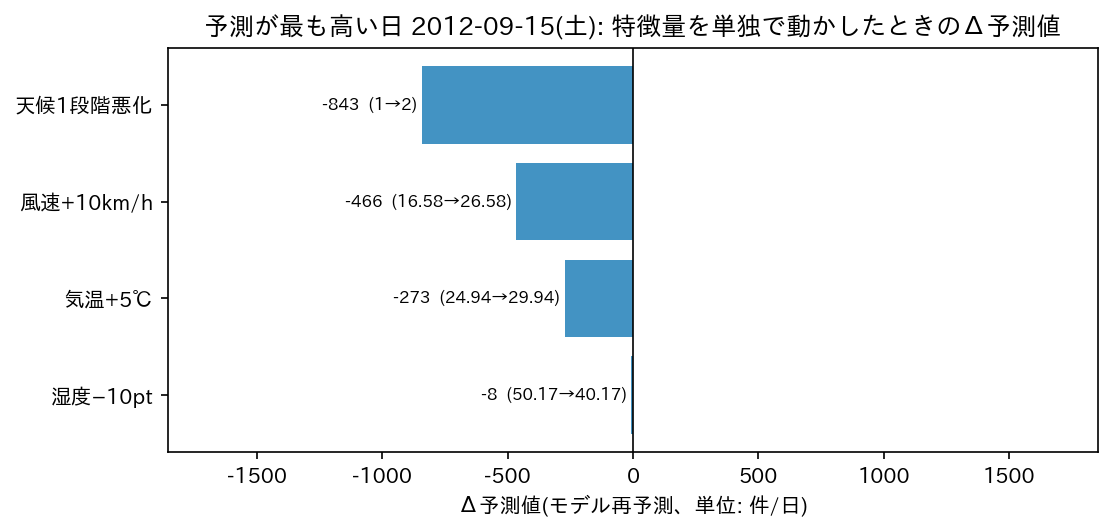

■ whatif_multi_day1.png  [生成I/F: xai_platform._core.plots.scenario_dshap]


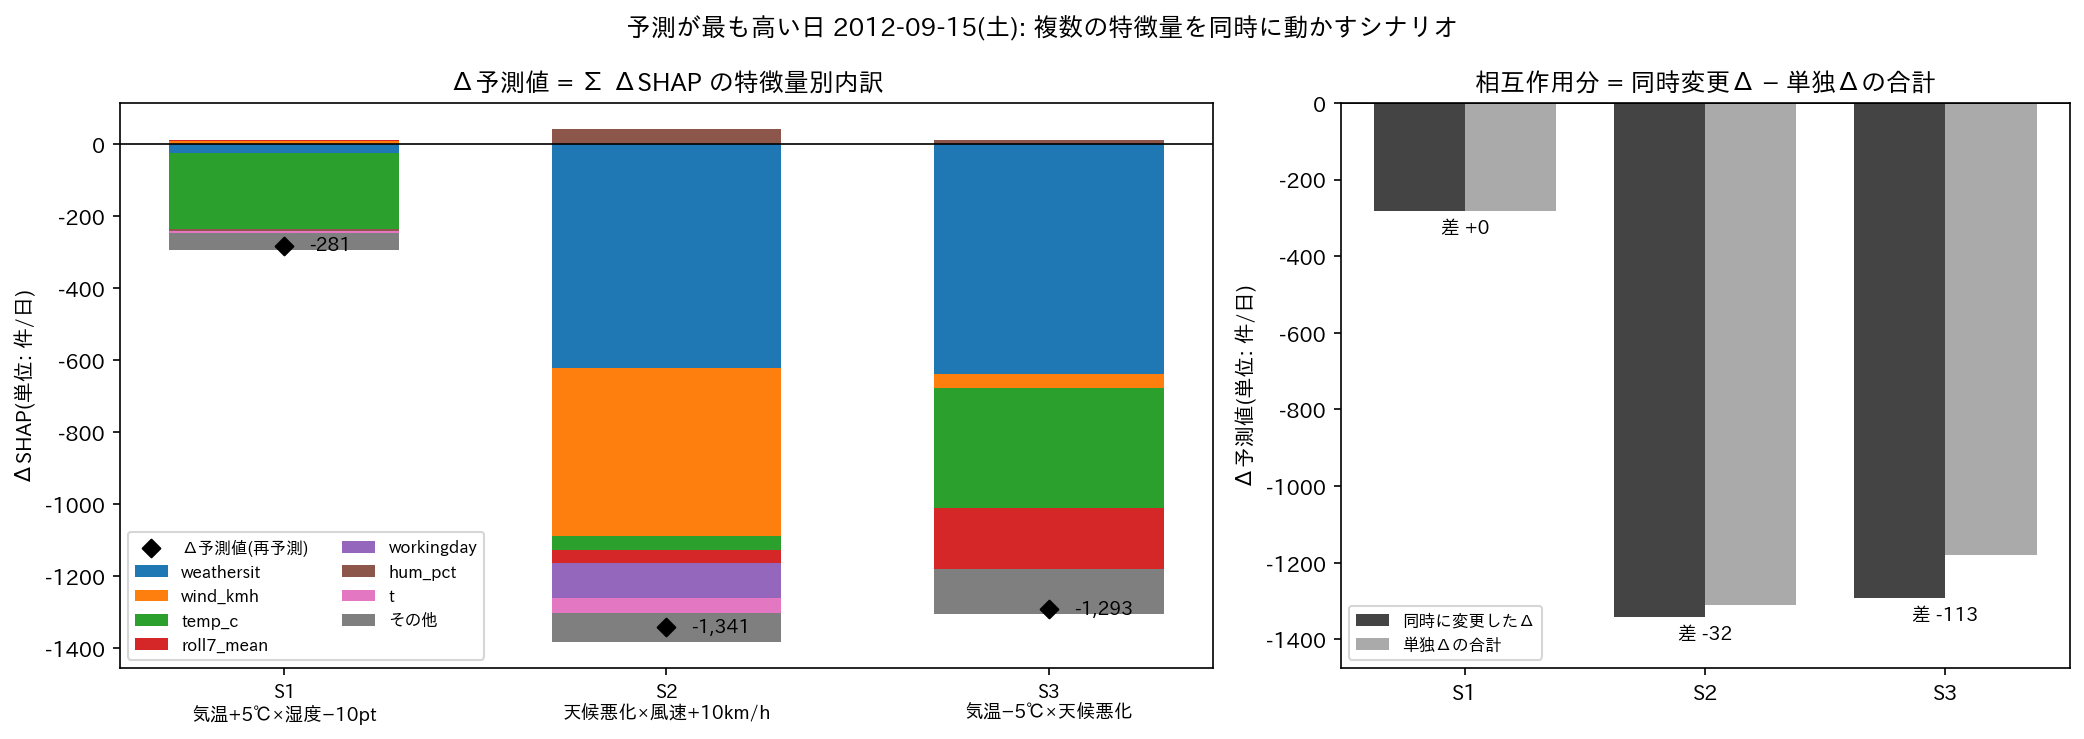

■ whatif_single_day2.png  [生成I/F: xai_platform._core.plots.tornado]


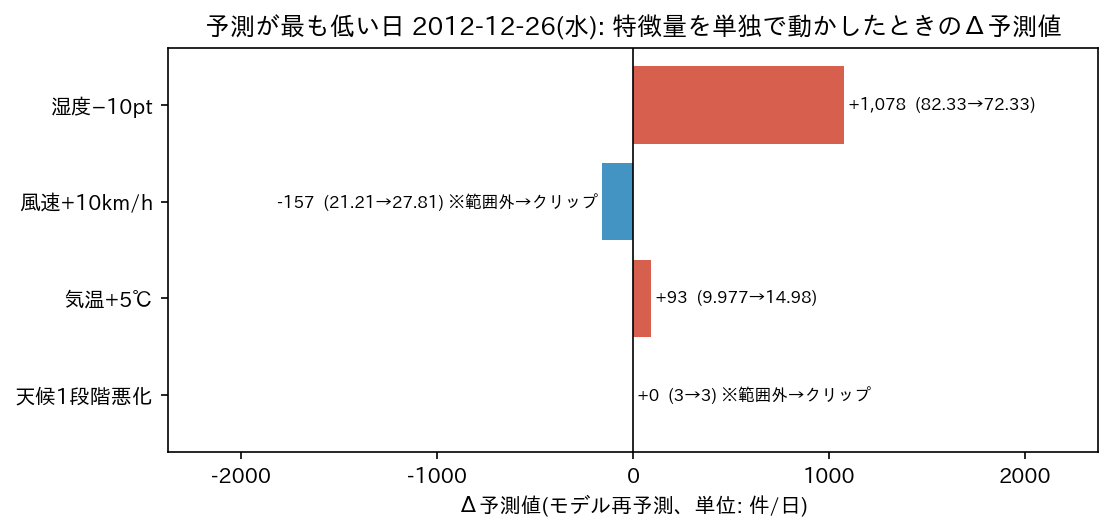

■ whatif_multi_day2.png  [生成I/F: xai_platform._core.plots.scenario_dshap]


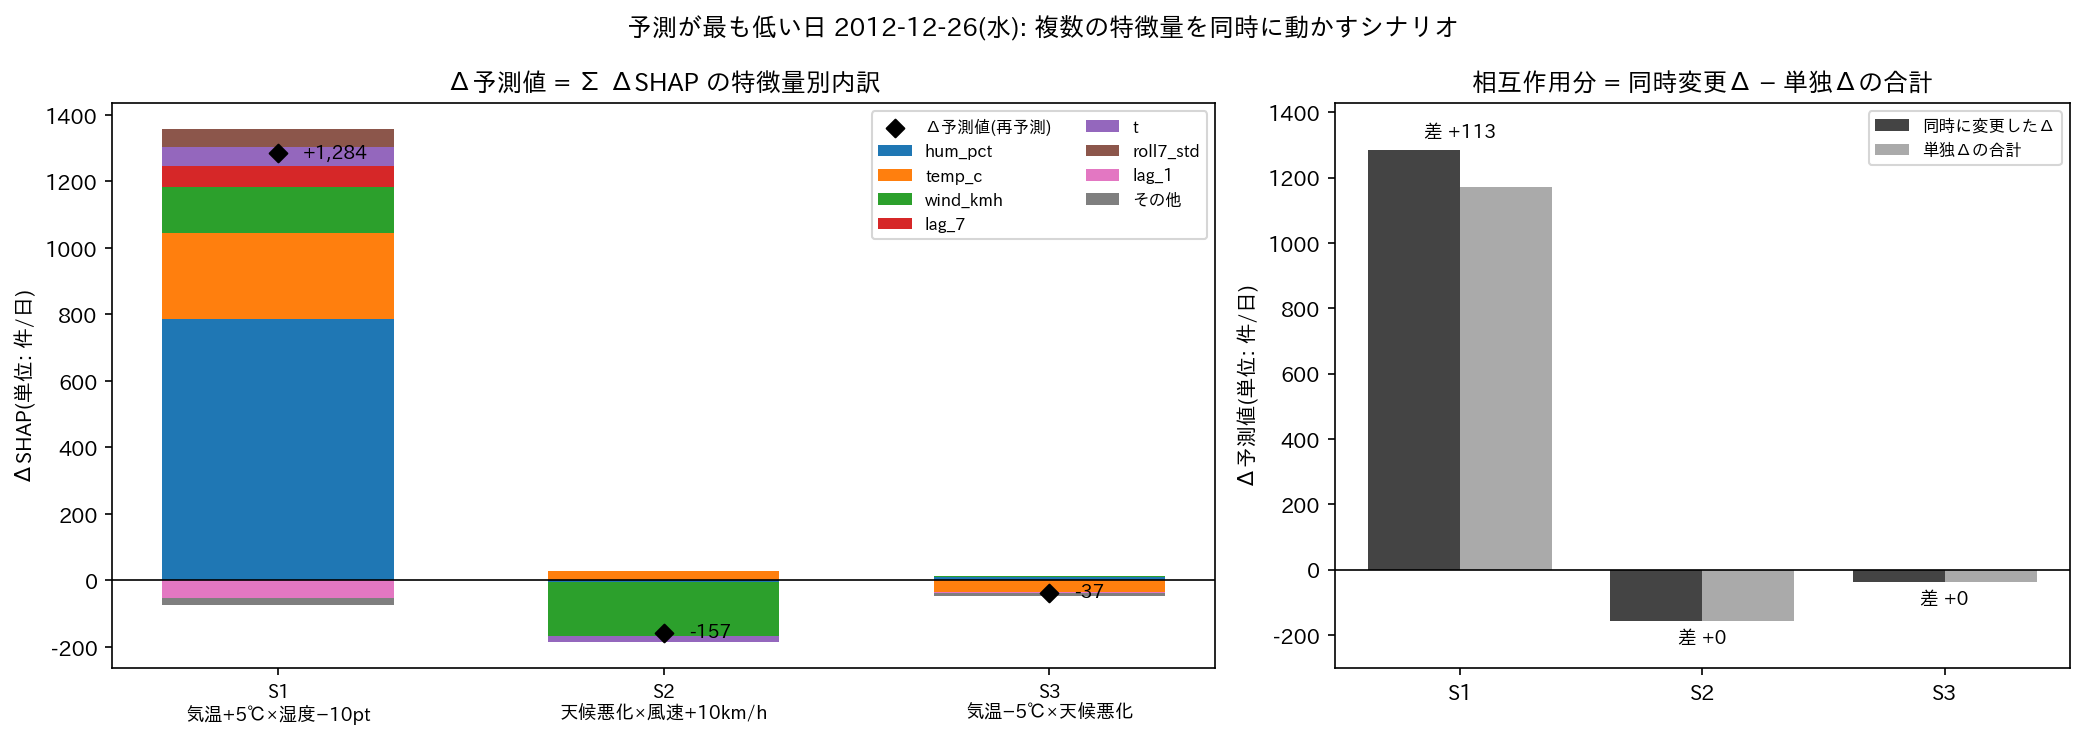

■ whatif_single_day3.png  [生成I/F: xai_platform._core.plots.tornado]


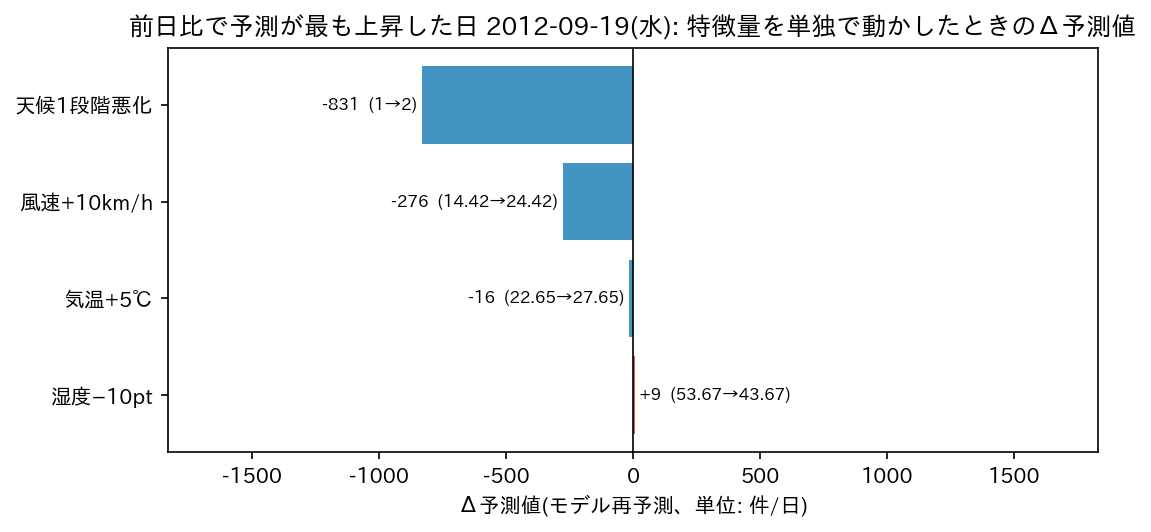

■ whatif_multi_day3.png  [生成I/F: xai_platform._core.plots.scenario_dshap]


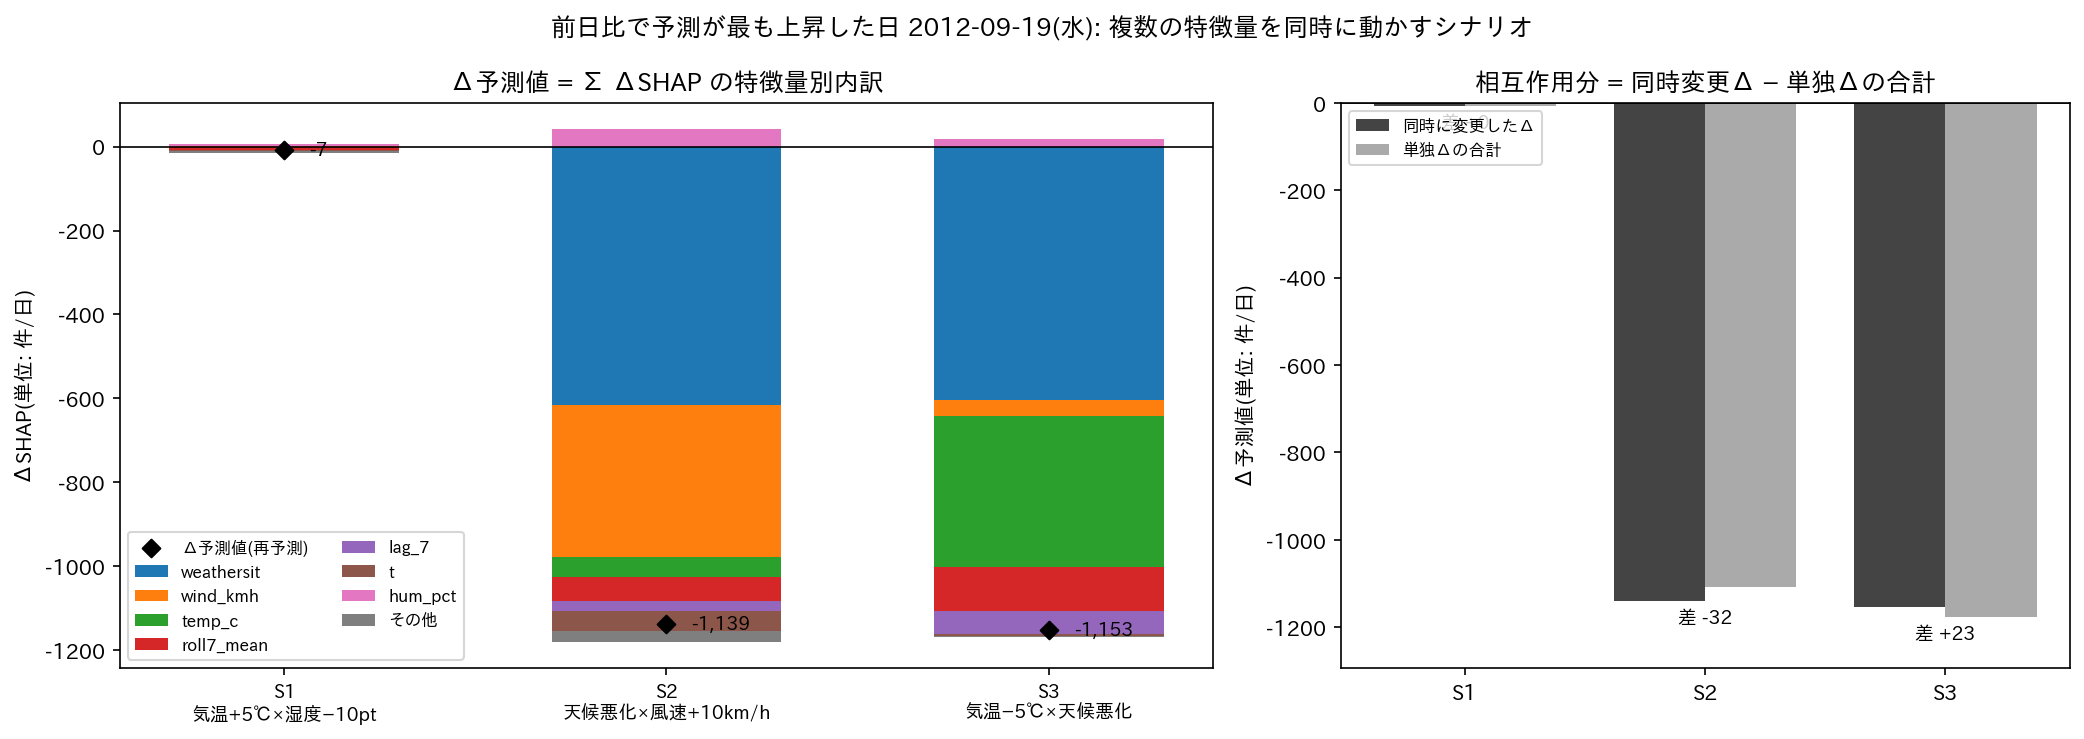

■ whatif_single_day4.png  [生成I/F: xai_platform._core.plots.tornado]


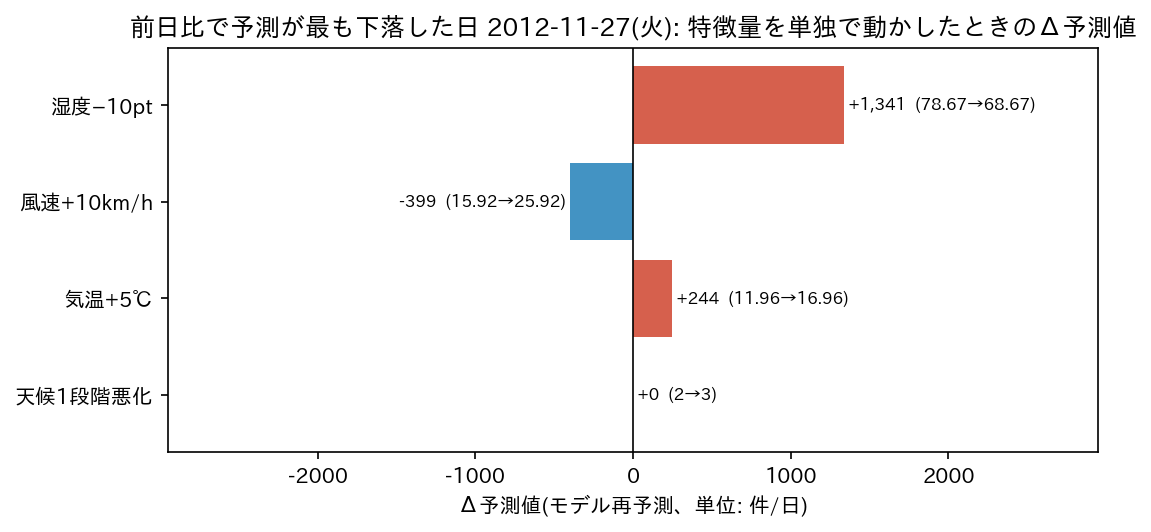

■ whatif_multi_day4.png  [生成I/F: xai_platform._core.plots.scenario_dshap]


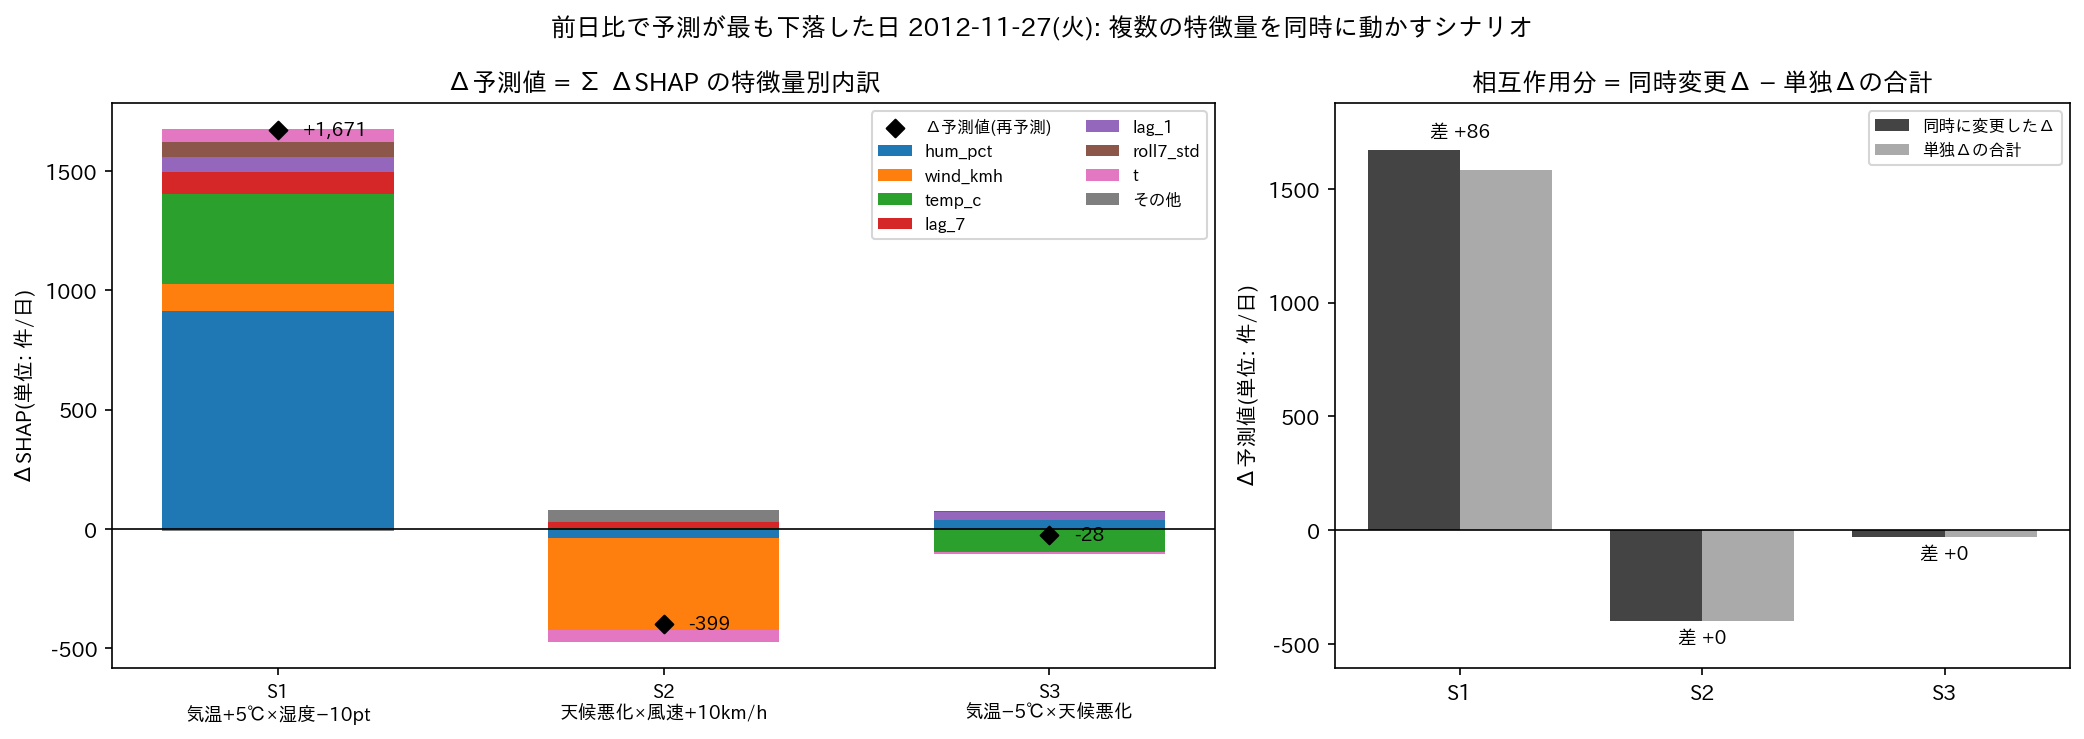

■ whatif_single_day5.png  [生成I/F: xai_platform._core.plots.tornado]


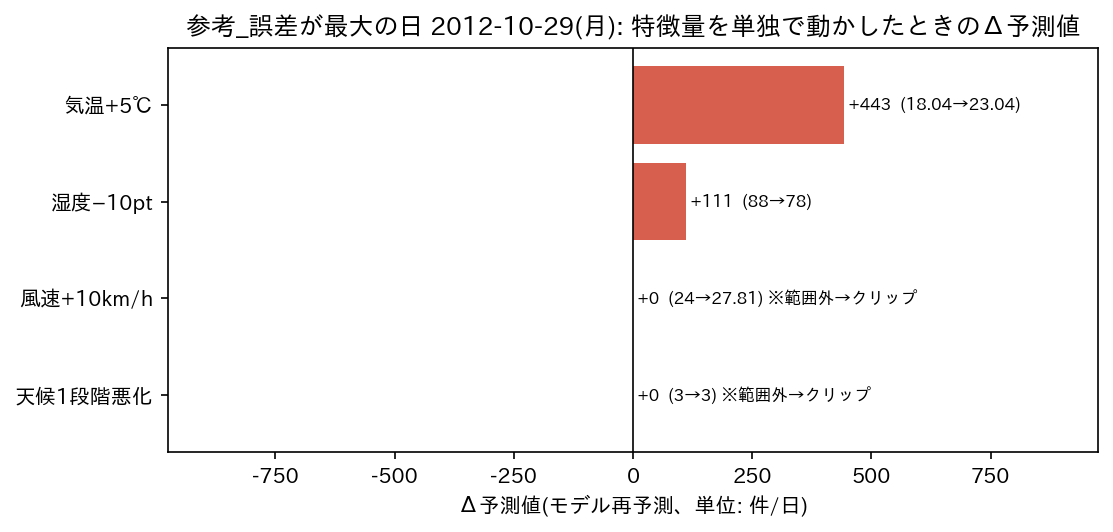

■ whatif_multi_day5.png  [生成I/F: xai_platform._core.plots.scenario_dshap]


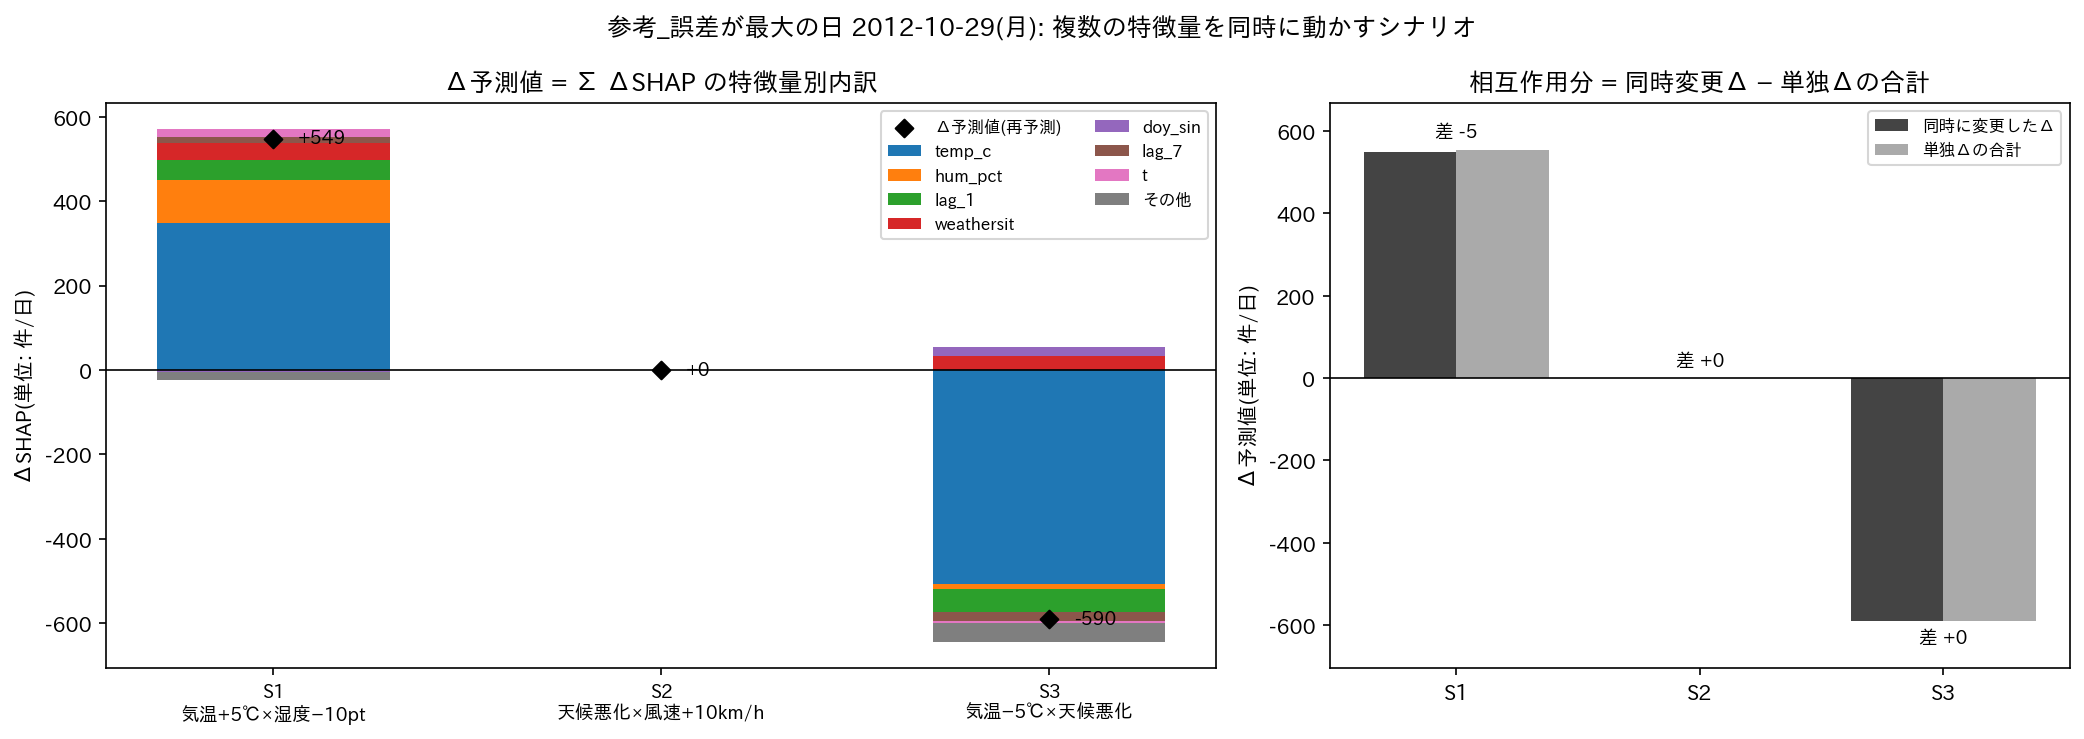

■ whatif_period.png  [生成I/F: xai_platform._core.plots.period_whatif]


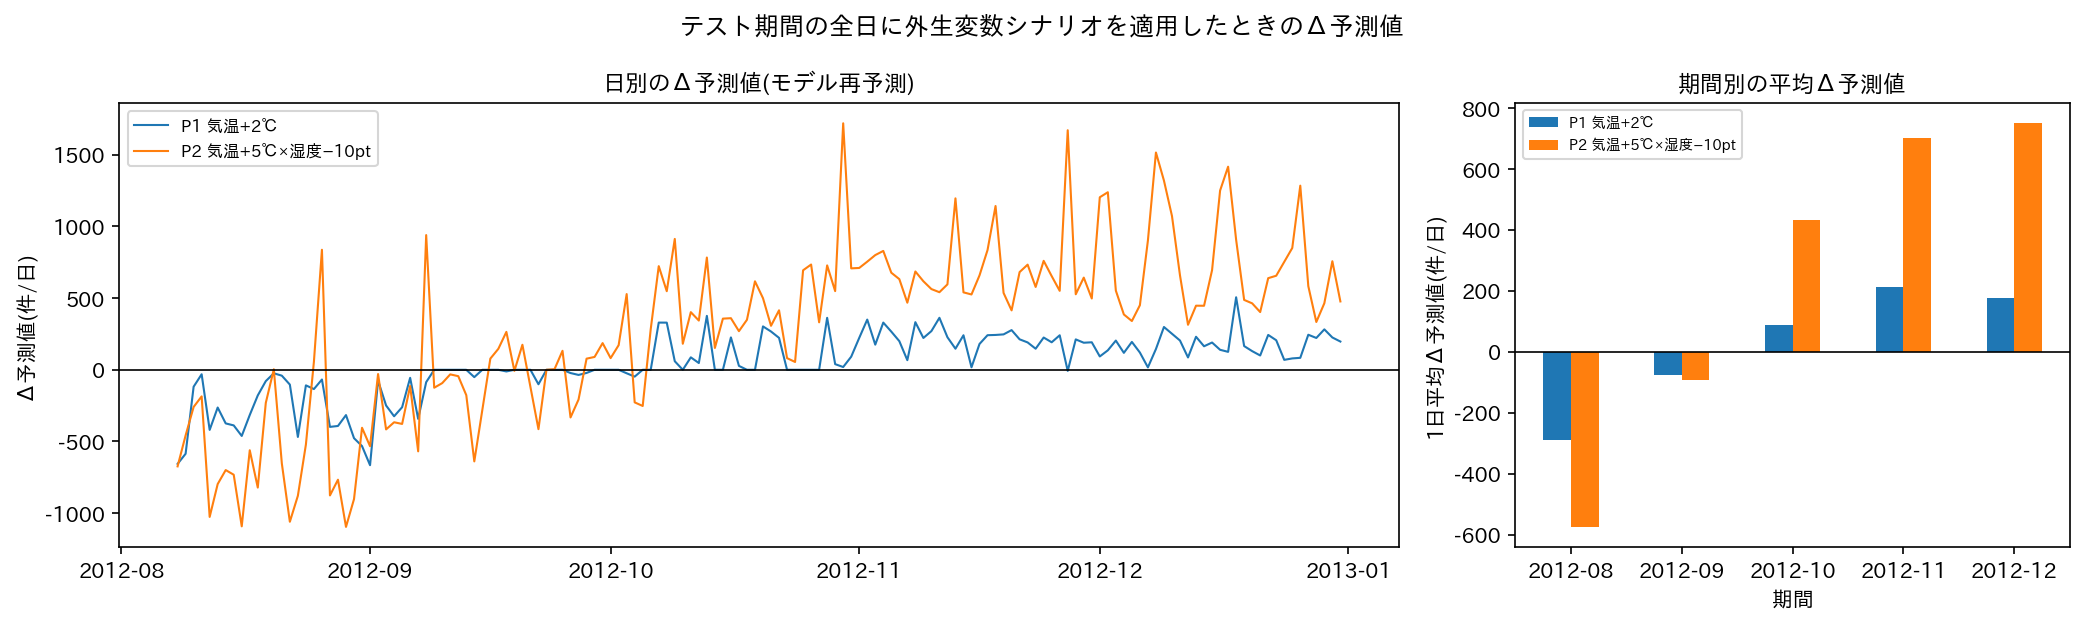

In [8]:
a.step_whatif().show()

In [9]:
a.finalize()
MANIFEST.to_frame(a.out.root).head(60)

,ファイル,種類,生成I/F,I/Fの説明,SHAP描画関数,分析ステップ
0,tables/data_periods.csv,表,アプリ側で作成,,,1. データ確認
1,tables/feature_descriptions.csv,表,アプリ側で作成,,,1. データ確認
2,figures/series_split.png,図,plots.series_with_split,目的変数の推移と訓練/テストの境界。,,1. データ確認
3,tables/accuracy.csv,表,model.accuracy_table,テスト期間の RMSE・MAE・MAPE・sMAPE(Naive を含むモデル比較)。,,2. 精度比較(Naive含む)
4,tables/accuracy_excl_outlier.csv,表,model.accuracy_table,テスト期間の RMSE・MAE・MAPE・sMAPE(Naive を含むモデル比較)。,,2. 精度比較(Naive含む)
5,figures/test_predictions.png,図,plots.test_predictions,テスト期間の実測値と各モデルの予測値。,,2. 精度比較(Naive含む)
6,tables/additivity_check.csv,表,xai_platform.analyzer.ShapAnalyzer.additivity,加法性チェック(モデル出力・予測値)の最大絶対誤差と合否。,,3. SHAP計算と検証
7,tables/ridge_shap_check.csv,表,explain.ridge_check,Ridge(標準化→Ridge)の SHAP が 係数 × (x − 訓練平均) と一致する...,,3. SHAP計算と検証
8,tables/group_lgbm_vs_ridge.csv,表,アプリ側で作成,,,3. SHAP計算と検証
9,tables/representative_days.csv,表,explain.select_days,代表日の選定(テスト期間内)。同じ日が重なったら次点を採る。,,4. 代表日の分解(ミクロ)
